# 02 — Exploring the queue: survival curves, the map, the drivers and the state archetypes

What the cleaned queue file shows before any model: operation and withdrawal over time by region, technology and size (F1–F3, F8), the six drivers of five-year completion (F19), where and when requests die (F20), the U.S. map of the queue and the built fleet (F9) and the state archetypes (F25).

**Inputs → Outputs**

| Part | Was | What it does |
|---|---|---|
| A | notebook 03 | Explore survival curves |
| B | notebook 03b | Where the queue and the built fleet are (figure F9) |

*Execution order:* Runs after notebook 01. Paths are relative to the repository root.

*Part A*

| | Path | Notes |
|---|---|---|
| in | `data/interim/queue_clean.parquet` | notebook 02 |
| in | `data/raw/lbnl/lbnl_ix_queue_data_file_thru2024_v2.xlsx` | LBNL's summary sheets 22, 23, 25, 31, 38 (benchmarks) |
| out | `results/cif_curves.csv`, `results/cif_horizons.csv` | curves on a monthly grid and at 3/5/7 years, with 95% bootstrap bands |
| out | `results/trackA_event_counts.csv`, `results/mockup_check.csv` | sample, outcomes, naive mock-up check |
| out | `results/five_year_by_size.csv`, `results/five_year_by_congestion.csv` | data behind F3 and F8 |
| out | `results/drivers_5yr.csv` | five-year completion by six drivers, by region, Wilson intervals (F19) |
| out | `results/hazards_by_queue_year.csv`, `results/exit_stage.csv`, `results/exit_timing.csv`, `results/completion_given_survival.csv` | when and where requests die (F20) |
| out | `results/benchmarks.csv`, `results/explore_checks.csv` | LBNL vs this file; acceptance checks |
| out | `figures/F1_*`, `F2_*`, `F3_*`, `F8_*`, `F19_*`, `F20_*` (report candidates), `figures/02_eda/*` | 6 report figures + 9 exploratory figures |

*Part B*

| | Path | Notes |
|---|---|---|
| in | `data/interim/queue_clean.parquet` | notebook 02 — every request, status at end-2024, county FIPS |
| in | `data/raw/eia860m/eia860m_2026-07.parquet` | notebook 01 — operable generators with coordinates |
| in | `data/raw/geo/cb_2020_us_county_20m.zip`, `cb_2020_us_state_20m.zip` | U.S. Census Bureau cartographic boundary files (public domain), SHA-256 in `data/raw/geo/SHA256.txt` |
| out | `results/map_unmatched.csv` | requests without a usable county code, by region |
| out | `results/map_counts_by_state.csv` | requests and MW by state and status |
| out | `results/map_built_share_by_state.csv` | share of resolved 2010–2018 entrants that reached operation, by state |
| out | `figures/F9_project_map.png/.svg`, `figures/02_eda/03b_02_built_share_by_state.png/.svg` | figure F9 and its companion |
| out | `results/map_checks.csv` | this notebook's checks, PASS/FAIL |
| out | `results/state_archetypes.csv`, `results/archetype_profiles.csv`, `figures/F25_state_archetypes.*` | state archetypes from k-means on market features, validated on 2017–2019 outcomes (section 5) |

# Part A — Explore survival curves (was notebook 03)

This notebook estimates, for the three Track A regions, how fast requests
reach operation and how fast they withdraw — by region, technology, entry
cohort, size and queue congestion — with Aalen–Johansen cumulative incidence
curves and bootstrap bands, and checks the data against LBNL's own published
summaries.

## Setup

Survival estimates come from `src/survival_tools.py` (Aalen–Johansen, written
out in numpy and checked against lifelines in `tests/test_survival_tools.py`);
outcomes from `src/events.py`; congestion from `src/features.py`. Every curve
has a 95% percentile band from 500 bootstrap resamples of projects.
`draw()` plots one curve with its band.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.append(str(Path.cwd().resolve().parent))  # notebooks run from notebooks/; src/ is one level up
from src import benchmarks, config, drivers, events, features, get_lbnl, paths, plots, survival_tools

paths.ensure_dirs()
plots.set_style()
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)

NOTEBOOK = "02_eda"
TRACK_A = config.TRACK_A_REGIONS


def save(fig, name, caption):
    """Save a figure of this notebook under figures/02_eda/ with its caption stub."""
    return plots.save_fig(fig, name, caption, NOTEBOOK, folder=NOTEBOOK)


def pct(x, digits=1):
    """Format a share as a percentage string."""
    return f"{100 * x:.{digits}f}%"


TIMES = np.arange(0, 121) / 12  # monthly grid, 0–10 years
HORIZONS = config.HORIZONS
N_BOOT = 500
SEED = 2026
CAUSE = {"operation": "cif_operation", "withdrawal": "cif_withdrawal", "still in queue": "survival"}
COHORT_COLORS = {"2000–09": "#6BAED6", "2010–14": "#2171B5", "2015–19": "#08306B"}  # one hue, light → dark


def draw(ax, curve, column, color, label, band=True):
    """Step plot of one curve with its bootstrap band."""
    ax.step(curve["time"], curve[column], where="post", color=color, label=label)
    if band:
        ax.fill_between(curve["time"], curve[f"{column}_low"], curve[f"{column}_high"], step="post",
                        color=color, alpha=0.15, linewidth=0)


def at_horizons(curves, keys, column, horizons=HORIZONS):
    """Estimate and band of one curve at the report horizons, one row per group."""
    rows = curves[np.isin(curves["time"].round(6), horizons)]
    table = rows[keys + ["n", "time", column, f"{column}_low", f"{column}_high"]].copy()
    table["value"] = (table[column].map(lambda v: f"{v:.1%}") + " ("
                      + table[f"{column}_low"].map(lambda v: f"{v:.1%}") + "–"
                      + table[f"{column}_high"].map(lambda v: f"{v:.1%}") + ")")
    return table.pivot_table(index=keys + ["n"], columns="time", values="value", aggfunc="first")


all_curves, all_horizons = [], []


def keep(curves, grouping, keys):
    """Store a set of curves for results/cif_curves.csv and results/cif_horizons.csv."""
    tagged = curves.assign(grouping=grouping, group=curves[keys].astype(str).agg(" | ".join, axis=1))
    all_curves.append(tagged)
    all_horizons.append(tagged[np.isin(tagged["time"].round(6), HORIZONS)])

## 1. Outcomes and the Track A sample

`events.code_events()` gives every clean request an outcome — operation,
withdrawal, or still in the queue at 2024-12-31 (censored) — and the time from
its request. Withdrawals dated after the censor date are censored, because on
2024-12-31 those projects were still waiting (notebook 02, figure 02_08).

In [2]:
clean = pd.read_parquet(paths.DATA_INTERIM / "queue_clean.parquet")
coded = events.code_events(clean)
sample = events.track_a_sample(coded)
sample["outcome"] = sample["event"].map(events.EVENT_NAMES)
sample["tech_group"] = sample["type_clean"].map(plots.tech_group)
sample["cohort"] = events.entry_cohort(sample["q_year"])
sample["size_regime"] = features.size_regime(sample["mw"])

counts = pd.crosstab(sample["region"], sample["outcome"], margins=True).reindex(TRACK_A + ["All"])
counts.to_csv(paths.RESULTS / "trackA_event_counts.csv")
excluded = (coded[coded["region"].isin(TRACK_A)].assign(exclusion=lambda t: t["exclusion"].replace("", "in sample"))
            .groupby(["region", "exclusion"]).size().unstack(fill_value=0))
print(f"Track A sample: {len(sample):,} requests")
print("Censored because withdrawn after the censor date:",
      int(((sample["q_status"] == "withdrawn") & (sample["event"] == 0)).sum()))
counts

Track A sample: 13,366 requests
Censored because withdrawn after the censor date: 150


outcome,censored,operation,withdrawal,All
region,,,,
ERCOT,1724,379,889,2992
PJM,2208,1143,4549,7900
CAISO,640,208,1626,2474
All,4572,1730,7064,13366


In [3]:
excluded

exclusion,in sample,no valid request date,operational without operation date,withdrawn without withdrawal date
region,,,,
CAISO,2474,7,13,343
ERCOT,2992,268,17,0
PJM,7900,24,23,152


**Reading this.** The Track A sample has 13,366 requests: 2,992 in ERCOT, 7,900 in PJM and 2,474 in CAISO. By the end of 2024, 1,730 had reached operation, 7,064 had withdrawn and 4,572 were still in the queue (censored), including 150 withdrawn projects whose withdrawal is dated after the censor date. The sample is smaller than notebook 01's 13,733 candidates because cleaning removed non-generation rows and because the timing model needs a valid request date: ERCOT loses 268 requests for that reason, CAISO loses 343 withdrawn rows without a withdrawal date, and PJM 152. Roughly one completion for every four withdrawals, as PLAN.md expected for notebook 04.

## 2. A data artefact: ERCOT's bulk withdrawal date

Before drawing any curve, the withdrawal dates are checked for dates shared by
many projects. A single date carried by hundreds of withdrawals is more likely
the day a record was captured than the day each project left.

In [4]:
withdrawn = coded[coded["region"].isin(TRACK_A) & (coded["q_status"] == "withdrawn") & coded["wd_date"].notna()]
most_common = withdrawn.groupby("region")["wd_date"].agg(lambda s: s.value_counts().index[0])
stamp = pd.DataFrame({
    "withdrawals with a date": withdrawn.groupby("region").size(),
    "earliest withdrawal date": withdrawn.groupby("region")["wd_date"].min().dt.date,
    "most common date": most_common.dt.date,
    "withdrawals on that date": withdrawn.groupby("region")["wd_date"].agg(lambda s: s.value_counts().iloc[0]),
}).reindex(TRACK_A)
stamp["share on that date"] = stamp["withdrawals on that date"] / stamp["withdrawals with a date"]
ercot_stamp = pd.Timestamp(most_common["ERCOT"])
bulk = (sample["region"] == "ERCOT") & (sample["wd_date"] == ercot_stamp)
print("ERCOT bulk-dated withdrawals in the Track A sample:", int(bulk.sum()), "of",
      int((sample["region"] == "ERCOT").sum()), "ERCOT requests; entry years",
      int(sample.loc[bulk, "q_year"].min()), "to", int(sample.loc[bulk, "q_year"].max()))
stamp.round(3)

ERCOT bulk-dated withdrawals in the Track A sample: 441 of 2992 ERCOT requests; entry years 2002 to 2017


,withdrawals with a date,earliest withdrawal date,most common date,withdrawals on that date,share on that date
region,,,,,
ERCOT,954,2018-08-29,2018-08-29,441,0.462
PJM,4685,1999-06-26,2024-12-18,456,0.097
CAISO,1628,2006-01-11,2008-11-26,64,0.039


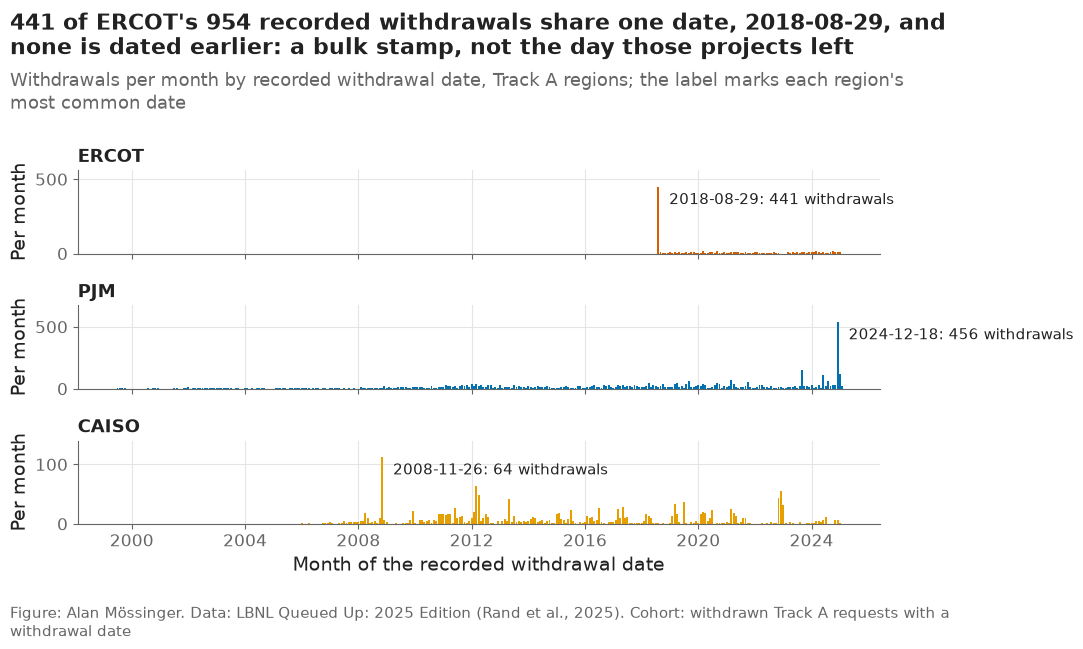

In [5]:
monthly = (withdrawn.assign(month=withdrawn["wd_date"].dt.to_period("M").dt.to_timestamp())
           .groupby(["region", "month"]).size())
fig, axes = plt.subplots(3, 1, sharex=True)
for ax, region in zip(axes, TRACK_A):
    series = monthly.loc[region]
    ax.bar(series.index, series.values, width=25, color=plots.region_color(region))
    ax.annotate(f"{stamp.loc[region, 'most common date']}: {stamp.loc[region, 'withdrawals on that date']} withdrawals",
                (series.idxmax(), series.max()), xytext=(8, -4), textcoords="offset points", fontsize=11, va="top")
    ax.set_title(region, fontsize=13)
    ax.set_ylabel("Per month")
    ax.set_ylim(0, series.max() * 1.25)
axes[-1].set_xlabel("Month of the recorded withdrawal date")
plots.finish(fig,
             f"{stamp.loc['ERCOT', 'withdrawals on that date']} of ERCOT's "
             f"{stamp.loc['ERCOT', 'withdrawals with a date']:,} recorded withdrawals share one date, "
             f"{stamp.loc['ERCOT', 'most common date']}, and none is dated earlier: a bulk stamp, not the day "
             "those projects left",
             "Withdrawals per month by recorded withdrawal date, Track A regions; the label marks each region's "
             "most common date",
             "withdrawn Track A requests with a withdrawal date")
save(fig, "03_10_withdrawal_date_spikes",
     "Number of withdrawals per month by recorded withdrawal date in CAISO, ERCOT and PJM, showing ERCOT's "
     "single bulk withdrawal date.")
plt.show()

How much does the stamp matter? The ERCOT curves for 2000–2019 entrants are
recomputed with the bulk-dated withdrawals dropped. Dropping them is not a fix
(it removes failures and so inflates completion); it only shows how sensitive
each quantity is to those rows.

In [6]:
ercot_early = sample[(sample["region"] == "ERCOT") & sample["q_year"].between(2000, 2019)]
rows = []
for label, part in [("as recorded", ercot_early),
                    ("bulk-dated withdrawals dropped", ercot_early[ercot_early["wd_date"] != ercot_stamp])]:
    fit = survival_tools.aalen_johansen(part["duration_years"], part["event"], [3.0, 5.0])
    rows.append({"ERCOT 2000–2019 entrants": label, "n": len(part),
                 "operation by 3 yr": fit["cif_operation"].iloc[0], "operation by 5 yr": fit["cif_operation"].iloc[1],
                 "withdrawal by 3 yr": fit["cif_withdrawal"].iloc[0], "withdrawal by 5 yr": fit["cif_withdrawal"].iloc[1]})
sensitivity = pd.DataFrame(rows)
sensitivity.to_csv(paths.RESULTS / "ercot_bulk_date_sensitivity.csv", index=False)
sensitivity.round(3)

,ERCOT 2000–2019 entrants,n,operation by 3 yr,operation by 5 yr,withdrawal by 3 yr,withdrawal by 5 yr
0,as recorded,1211,0.095,0.201,0.149,0.279
1,bulk-dated withdrawals dropped,770,0.149,0.316,0.194,0.284


**Reading this.** 441 of ERCOT's 954 dated withdrawals (46%) carry the same date, 2018-08-29, and no ERCOT withdrawal is dated earlier. They belong to projects that entered between 2002 and 2017, so the date cannot be when each of them left; it looks like the day ERCOT's withdrawn records were captured. PJM has its own spike — 456 withdrawals on 2024-12-18 (10% of its dated withdrawals) — which may be a real administrative deadline in its queue reform, but I have not verified it; CAISO's largest single date holds 64 (4%). The sensitivity table shows what is and is not affected. For ERCOT's 2000–2019 entrants, five-year operation is 20.1% as recorded; dropping the stamped rows would push it to 31.6%, but only because it removes 441 projects that really did fail, so they must stay in. What is wrong is their *timing*: those projects sit in the risk set until 2018 instead of leaving years earlier, so ERCOT's withdrawal curves, its time in queue and its congestion before August 2018 are distorted. How to treat these rows in the models is a decision for notebook 04 — **ASK ALAN** (options in `docs/journal.md`).

## 3. F1 — operation and withdrawal by region

The headline picture: cumulative incidence of operation and of withdrawal over
ten years from the request, by region. The two causes are estimated together
(Aalen–Johansen), so a withdrawal is never mistaken for "not yet built".

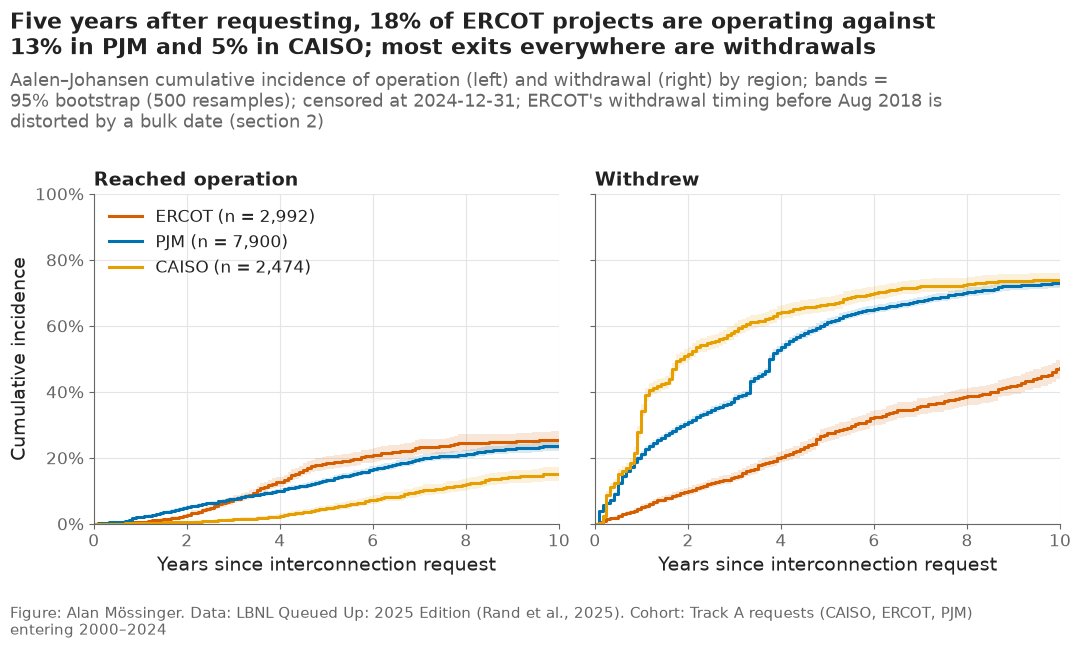

,time,3.0,5.0,7.0
region,n,,,
CAISO,2474,1.4% (0.8%–1.9%),4.8% (3.8%–5.8%),9.9% (8.4%–11.4%)
ERCOT,2992,7.5% (6.4%–8.7%),18.4% (16.5%–20.4%),23.3% (21.0%–25.6%)
PJM,7900,7.5% (7.0%–8.1%),13.2% (12.3%–14.0%),19.6% (18.6%–20.8%)


In [7]:
by_region = survival_tools.curves_by_group(sample, "region", TIMES, n_boot=N_BOOT, seed=SEED)
keep(by_region, "region", ["region"])

fig, axes = plt.subplots(1, 2, sharey=True)
for ax, (title, column) in zip(axes, [("Reached operation", "cif_operation"), ("Withdrew", "cif_withdrawal")]):
    for region in TRACK_A:
        curve = by_region[by_region["region"] == region]
        draw(ax, curve, column, plots.region_color(region), f"{region} (n = {curve['n'].iloc[0]:,})")
    ax.set_title(title)
    ax.set_xlabel("Years since interconnection request")
    ax.set_xlim(0, 10)
    ax.set_ylim(0, 1)
    ax.yaxis.set_major_formatter(lambda y, _: f"{y:.0%}")
axes[0].set_ylabel("Cumulative incidence")
axes[0].legend(loc="upper left")
five = by_region[by_region["time"] == 5].set_index("region")
plots.finish(fig,
             f"Five years after requesting, {five.loc['ERCOT', 'cif_operation']:.0%} of ERCOT projects are "
             f"operating against {five.loc['PJM', 'cif_operation']:.0%} in PJM and "
             f"{five.loc['CAISO', 'cif_operation']:.0%} in CAISO; most exits everywhere are withdrawals",
             "Aalen–Johansen cumulative incidence of operation (left) and withdrawal (right) by region; "
             f"bands = 95% bootstrap ({N_BOOT} resamples); censored at 2024-12-31; ERCOT's withdrawal timing "
             "before Aug 2018 is distorted by a bulk date (section 2)",
             "Track A requests (CAISO, ERCOT, PJM) entering 2000–2024")
plots.save_fig(fig, "F1_cif_by_region",
               "Cumulative incidence of reaching commercial operation and of withdrawing, by years "
               "since the interconnection request, for CAISO, ERCOT and PJM, with 95% bootstrap bands.",
               NOTEBOOK)
plt.show()
at_horizons(by_region, ["region"], "cif_operation")

In [8]:
at_horizons(by_region, ["region"], "cif_withdrawal")

,time,3.0,5.0,7.0
region,n,,,
CAISO,2474,58.5% (56.5%–60.8%),66.5% (64.4%–68.8%),72.1% (70.2%–74.3%)
ERCOT,2992,14.2% (13.0%–15.8%),27.4% (25.2%–29.5%),35.7% (33.2%–38.1%)
PJM,7900,38.1% (37.0%–39.2%),61.2% (60.0%–62.5%),67.6% (66.3%–68.8%)


**Reading this.** Five years after the request, 18.4% of ERCOT projects are operating, against 13.2% in PJM and 4.8% in CAISO; by seven years 23.3%, 19.6% and 9.9%. The bands are narrow (PJM's five-year band is 12.3–14.0%), so the regional ordering is not noise. Withdrawal dominates: by five years 66.5% of CAISO and 61.2% of PJM requests have withdrawn. ERCOT's withdrawal curve (27.4% at five years) rises slowly, but much of that is the bulk-date artefact of section 2, so ERCOT's withdrawal speed should not be read from this figure. For a developer the left panel is the useful one: the same project has roughly four times the chance of being built within five years in ERCOT as in CAISO. These are averages over all technologies and entry years; F2 and 03_03 split them.

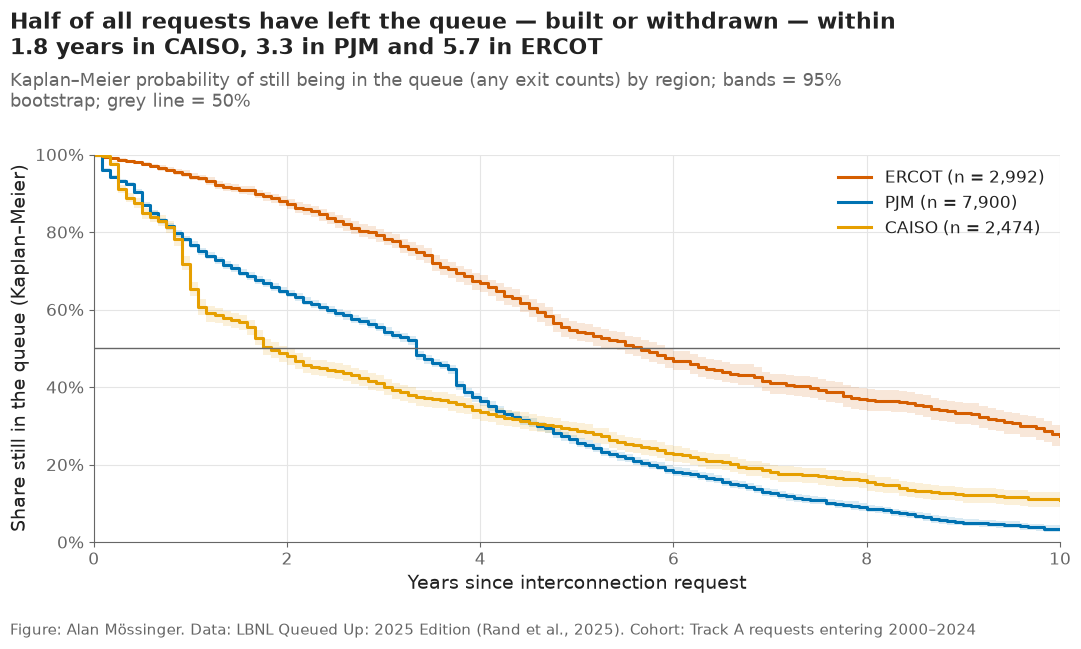

,ERCOT,PJM,CAISO
median years in queue (any exit),5.67,3.33,1.83


In [9]:
fig, ax = plt.subplots()
medians = {}
for region in TRACK_A:
    curve = by_region[by_region["region"] == region]
    draw(ax, curve, "survival", plots.region_color(region), f"{region} (n = {curve['n'].iloc[0]:,})")
    below = curve[curve["survival"] <= 0.5]
    medians[region] = below["time"].iloc[0] if len(below) else np.nan
ax.axhline(0.5, color=plots.MUTED, linewidth=1)
ax.set_xlim(0, 10)
ax.set_ylim(0, 1)
ax.yaxis.set_major_formatter(lambda y, _: f"{y:.0%}")
ax.set_xlabel("Years since interconnection request")
ax.set_ylabel("Share still in the queue (Kaplan–Meier)")
ax.legend(loc="upper right")
plots.finish(fig,
             f"Half of all requests have left the queue — built or withdrawn — within {medians['CAISO']:.1f} years "
             f"in CAISO, {medians['PJM']:.1f} in PJM and {medians['ERCOT']:.1f} in ERCOT",
             "Kaplan–Meier probability of still being in the queue (any exit counts) by region; bands = 95% "
             "bootstrap; grey line = 50%",
             "Track A requests entering 2000–2024")
save(fig, "03_01_still_in_queue_by_region",
     "Kaplan–Meier share of requests still in the queue by years since request, for CAISO, ERCOT and PJM.")
plt.show()
pd.Series(medians, name="median years in queue (any exit)").round(2).to_frame().T

**Reading this.** Half of all requests have left the queue — built or withdrawn — within 1.83 years in CAISO, 3.33 years in PJM and 5.67 years in ERCOT. CAISO clears its queue fastest because most of its requests withdraw early. ERCOT's 5.67 years is inflated by the bulk withdrawal date (section 2), which keeps hundreds of long-gone projects "in the queue" until 2018.

## 4. The naive mock-up, checked with the proper estimator

Notebook 01 found 4% / 21% / 15% five-year completion for 2010–2018 generation
entrants by simple counting. Every one of them has at least six years of
follow-up, so the Aalen–Johansen estimate at five years should match within
one point; this is the plan's check for notebook 03.

In [10]:
mock_sample = sample[sample["q_date"].dt.year.between(*config.MOCKUP_YEARS)]
rows = []
for region in TRACK_A:
    part = mock_sample[mock_sample["region"] == region]
    fit = survival_tools.aalen_johansen(part["duration_years"], part["event"], [5.0])
    rows.append({"region": region, "n": len(part), "aj_5yr": fit["cif_operation"].iloc[0],
                 "plan": config.MOCKUP_EXPECTED[region]})
mockup = pd.DataFrame(rows)
mockup["difference_points"] = 100 * (mockup["aj_5yr"] - mockup["plan"])
mockup["within_1_point"] = mockup["difference_points"].abs() <= 1
mockup.to_csv(paths.RESULTS / "mockup_check.csv", index=False)
mockup.round(4)

,region,n,aj_5yr,plan,difference_points,within_1_point
0,ERCOT,655,0.2137,0.21,0.3740,True
1,PJM,2731,0.1531,0.15,0.3057,True
2,CAISO,1064,0.0414,0.04,0.1353,True


**Reading this.** With the proper estimator, five-year completion for 2010–2018 entrants is 21.4% in ERCOT, 15.3% in PJM and 4.1% in CAISO, within 0.4 points of notebook 01's simple counts (21%, 15%, 4%). The check passes. The match is expected rather than lucky: every one of these entrants had more than five years of follow-up, so there is no censoring before five years and Aalen–Johansen reduces to counting. It confirms that the estimator and the event coding agree with the raw data.

## 5. F2 — operation by technology within each region

Technology groups with at least 50 requests in a region are drawn. The axis is
cut at 50% so differences are visible (stated on the figure).

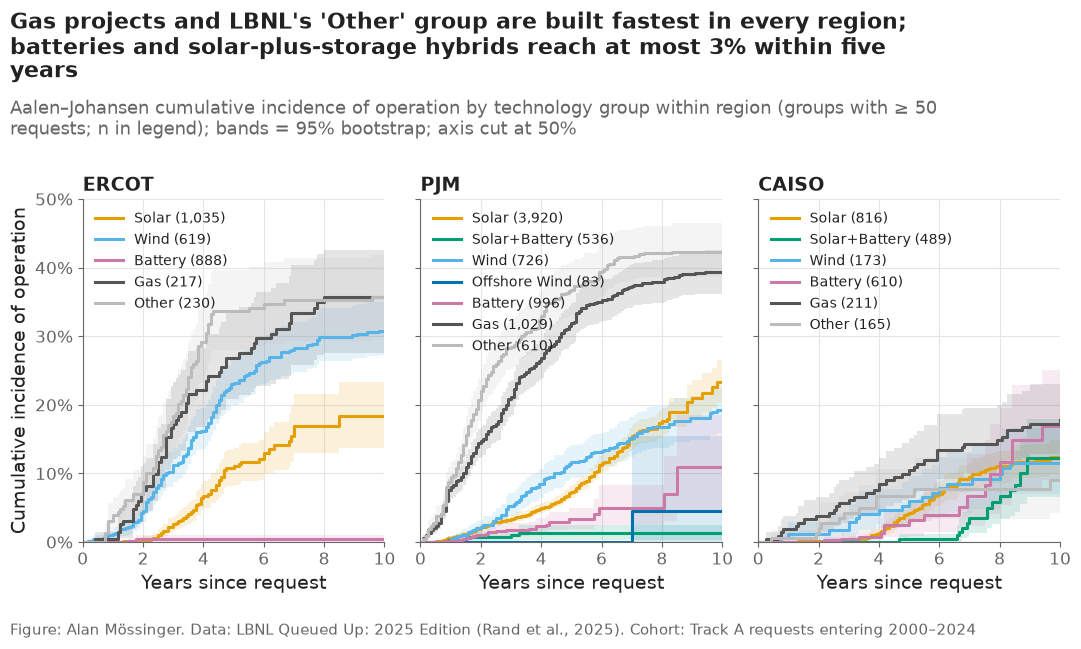

time                                       3.0                  5.0                  7.0
region tech_group    n                                                                  
CAISO  Battery       610      0.5% (0.0%–1.3%)     3.2% (0.9%–6.1%)    6.7% (2.4%–12.8%)
       Gas           211      6.2% (3.3%–9.5%)   10.5% (6.7%–15.2%)  14.4% (10.1%–19.6%)
       Other         165      4.2% (1.3%–7.4%)    6.7% (2.6%–10.7%)    7.8% (3.3%–12.3%)
       Solar         816      0.4% (0.0%–0.9%)     4.2% (2.9%–5.6%)    9.5% (7.3%–11.6%)
       Solar+Battery 489      0.0% (0.0%–0.0%)     0.4% (0.0%–1.2%)     3.5% (1.3%–6.3%)
       Wind          173      2.9% (0.6%–5.6%)     5.9% (2.9%–9.6%)    8.4% (4.3%–13.2%)
ERCOT  Battery       888      0.4% (0.0%–1.0%)     0.4% (0.0%–1.0%)     0.4% (0.0%–1.0%)
       Gas           217   17.2% (12.1%–23.3%)  26.9% (20.8%–33.4%)  33.4% (25.8%–40.4%)
       Other         230   18.3% (13.7%–23.3%)  33.7% (28.0%–39.6%)  35.2% (29.3%–41.4%)
       Solar         1035     2.6% (1.5%–3.8%)   11.1% (8.3%–13.7%)  17.0% (13.0%–21.5%)
       Wind          619    11.2% (8.8%–13.8%)  23.2% (20.0%–26.7%)  28.2% (24.8%–32.0%)
PJM    Battery       996      1.8% (0.9%–2.7%)     3.4% (1.9%–4.9%)     5.0% (2.5%–8.3%)
       Gas           1029  21.1% (18.5%–23.6%)  31.9% (28.8%–34.8%)  37.3% (34.3%–40.5%)
       Offshore Wind 83       0.0% (0.0%–0.0%)     0.0% (0.0%–0.0%)    4.6% (0.0%–15.5%)
       Other         610   28.5% (25.3%–32.2%)  36.7% (33.0%–40.9%)  41.6% (37.9%–45.5%)
       Solar         3920     3.4% (2.8%–3.9%)     7.4% (6.4%–8.4%)  15.4% (13.6%–17.1%)
       Solar+Battery 536      1.0% (0.2%–1.9%)     1.3% (0.4%–2.4%)     1.3% (0.4%–2.4%)
       Wind          726      5.3% (3.7%–7.2%)   11.6% (9.4%–14.1%)  15.1% (12.4%–18.2%)

In [11]:
by_tech = survival_tools.curves_by_group(sample, ["region", "tech_group"], TIMES, n_boot=N_BOOT,
                                         seed=SEED + 100, min_n=50)
keep(by_tech, "region × technology", ["region", "tech_group"])
order = [g for g in config.TECH_COLORS if g in set(by_tech["tech_group"])]


def tech_panels(column, ylabel, ymax):
    """Three panels (one per region) of one curve by technology."""
    fig, axes = plt.subplots(1, 3, sharey=True)
    for ax, region in zip(axes, TRACK_A):
        part = by_tech[by_tech["region"] == region]
        for group in order:
            curve = part[part["tech_group"] == group]
            if len(curve):
                draw(ax, curve, column, config.TECH_COLORS[group], f"{group} ({curve['n'].iloc[0]:,})")
        ax.set_title(region)
        ax.set_xlim(0, 10)
        ax.set_ylim(0, ymax)
        ax.yaxis.set_major_formatter(lambda y, _: f"{y:.0%}")
        ax.set_xlabel("Years since request")
        ax.legend(loc="upper left", fontsize=10)
    axes[0].set_ylabel(ylabel)
    return fig, axes


fig, axes = tech_panels("cif_operation", "Cumulative incidence of operation", 0.5)
five_tech = by_tech[by_tech["time"] == 5].set_index(["region", "tech_group"])["cif_operation"]
best = five_tech.groupby("region").idxmax().map(lambda k: k[1])
storage = five_tech[five_tech.index.get_level_values("tech_group").isin(["Battery", "Solar+Battery"])]
plots.finish(fig,
             "Gas projects and LBNL's 'Other' group are built fastest in every region; batteries and solar-plus-"
             f"storage hybrids reach at most {storage.max():.0%} within five years",
             "Aalen–Johansen cumulative incidence of operation by technology group within region (groups with "
             "≥ 50 requests; n in legend); bands = 95% bootstrap; axis cut at 50%",
             "Track A requests entering 2000–2024")
plots.save_fig(fig, "F2_operation_by_technology",
               "Cumulative incidence of reaching operation by technology group, in small multiples for CAISO, "
               "ERCOT and PJM, with 95% bootstrap bands.", NOTEBOOK)
plt.show()
at_horizons(by_tech, ["region", "tech_group"], "cif_operation")

**Reading this.** Gas projects and LBNL's "Other" group are built fastest everywhere: at five years gas reaches 31.9% in PJM, 26.9% in ERCOT and 10.5% in CAISO, and "Other" reaches 36.7% in PJM and 33.7% in ERCOT. Wind is next in ERCOT (23.2%). Solar is slow in the early years and catches up later (PJM solar goes from 7.4% at five years to 15.4% at seven). Batteries and solar+battery hybrids barely reach operation within five years (at most 3.4%, PJM batteries) — but they are also the most recent requests, so their curves rest on young cohorts with short follow-up, and their later years are still unknown. The ordering of technologies is similar across regions, while the level is set by the region: CAISO's best group (gas) is below ERCOT's slowest established group (solar, 11.1%). This is why the baseline in notebook 05 uses region × technology cells, not technology alone.

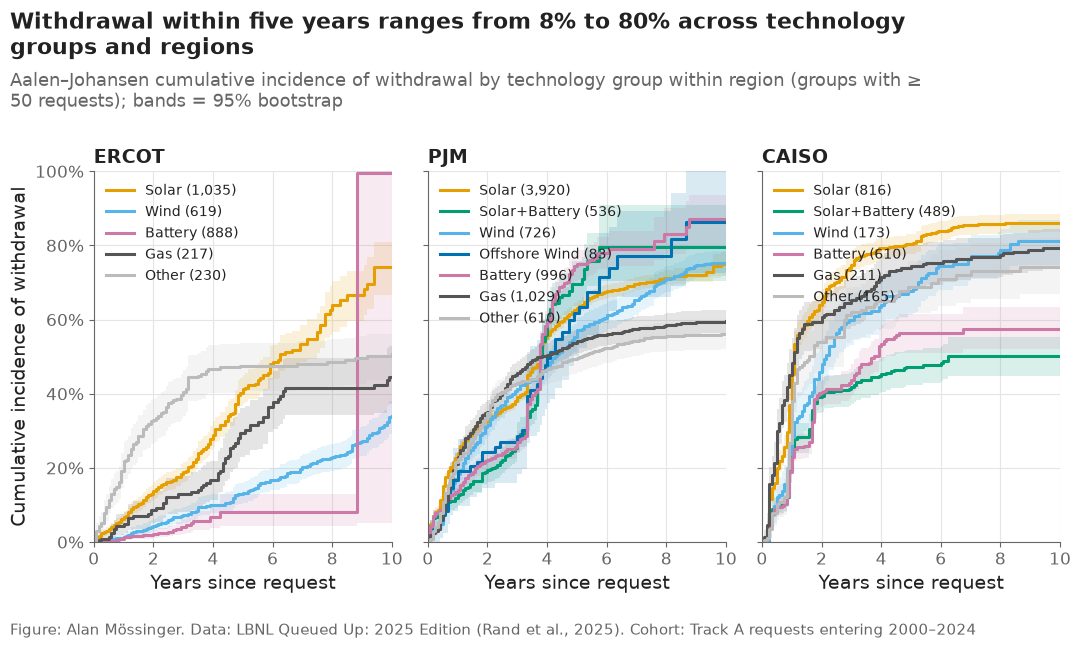

time                                       3.0                  5.0                  7.0
region tech_group    n                                                                  
CAISO  Battery       610   43.8% (39.7%–48.0%)  56.4% (51.1%–61.6%)  57.6% (52.2%–63.3%)
       Gas           211   65.4% (58.3%–71.3%)  74.4% (68.7%–80.1%)  76.9% (71.2%–82.0%)
       Other         165   62.0% (54.5%–68.8%)  68.7% (61.7%–75.8%)  73.2% (65.7%–80.6%)
       Solar         816   74.8% (71.6%–78.0%)  80.4% (77.6%–83.1%)  85.5% (82.8%–88.0%)
       Solar+Battery 489   41.8% (37.2%–45.9%)  47.3% (42.3%–51.8%)  50.1% (44.9%–55.2%)
       Wind          173   59.9% (53.3%–66.7%)  67.6% (61.3%–74.3%)  77.1% (71.0%–82.7%)
ERCOT  Battery       888      4.1% (2.2%–6.1%)    8.2% (4.3%–12.9%)    8.2% (4.3%–12.9%)
       Gas           217    12.9% (8.2%–17.9%)  29.5% (22.9%–36.1%)  41.5% (34.2%–49.6%)
       Other         230   40.5% (33.9%–46.4%)  47.6% (40.7%–53.6%)  48.1% (41.0%–54.2%)
       Solar         1035  18.8% (16.3%–21.7%)  41.2% (37.3%–45.1%)  53.4% (48.7%–58.6%)
       Wind          619      7.2% (5.2%–9.6%)  13.2% (10.5%–16.2%)  20.2% (17.1%–23.7%)
PJM    Battery       996   27.0% (24.1%–29.9%)  74.9% (70.7%–78.8%)  79.1% (74.4%–84.0%)
       Gas           1029  45.6% (42.2%–48.9%)  54.1% (50.9%–57.5%)  57.6% (54.4%–60.9%)
       Offshore Wind 83    28.6% (18.4%–39.1%)  61.8% (50.3%–74.3%)  77.2% (66.1%–89.4%)
       Other         610   42.9% (38.9%–46.5%)  49.8% (45.8%–53.6%)  54.2% (50.2%–57.9%)
       Solar         3920  39.1% (37.6%–40.8%)  63.1% (61.4%–64.9%)  69.5% (67.9%–71.4%)
       Solar+Battery 536   28.2% (24.4%–32.5%)  69.6% (63.6%–75.7%)  79.6% (70.3%–91.0%)
       Wind          726   41.3% (37.9%–44.9%)  57.1% (53.4%–60.7%)  65.2% (61.2%–68.8%)

In [12]:
fig, axes = tech_panels("cif_withdrawal", "Cumulative incidence of withdrawal", 1.0)
five_wd = by_tech[by_tech["time"] == 5].set_index(["region", "tech_group"])["cif_withdrawal"]
plots.finish(fig,
             f"Withdrawal within five years ranges from {five_wd.min():.0%} to {five_wd.max():.0%} across "
             "technology groups and regions",
             "Aalen–Johansen cumulative incidence of withdrawal by technology group within region (groups with "
             "≥ 50 requests); bands = 95% bootstrap",
             "Track A requests entering 2000–2024")
save(fig, "03_02_withdrawal_by_technology",
     "Cumulative incidence of withdrawal by technology group within CAISO, ERCOT and PJM.")
plt.show()
at_horizons(by_tech, ["region", "tech_group"], "cif_withdrawal")

**Reading this.** Withdrawal within five years ranges from 8.2% (ERCOT batteries) to 80.4% (CAISO solar). In PJM, batteries (74.9%) and solar+battery hybrids (69.6%) withdraw at five years about as often as solar (63.1%) — storage is not built quickly, it drops out. ERCOT's low withdrawal shares are partly the bulk-date artefact. Read together with F2, most of the gap between technologies is in how often they withdraw, not how fast the survivors finish.

## 6. Entry cohorts: has it become harder to get built?

Three entry cohorts (2000–09, 2010–14, 2015–19); the 2015–19 curves are
censored after five to nine years, so their right ends rest on fewer projects.

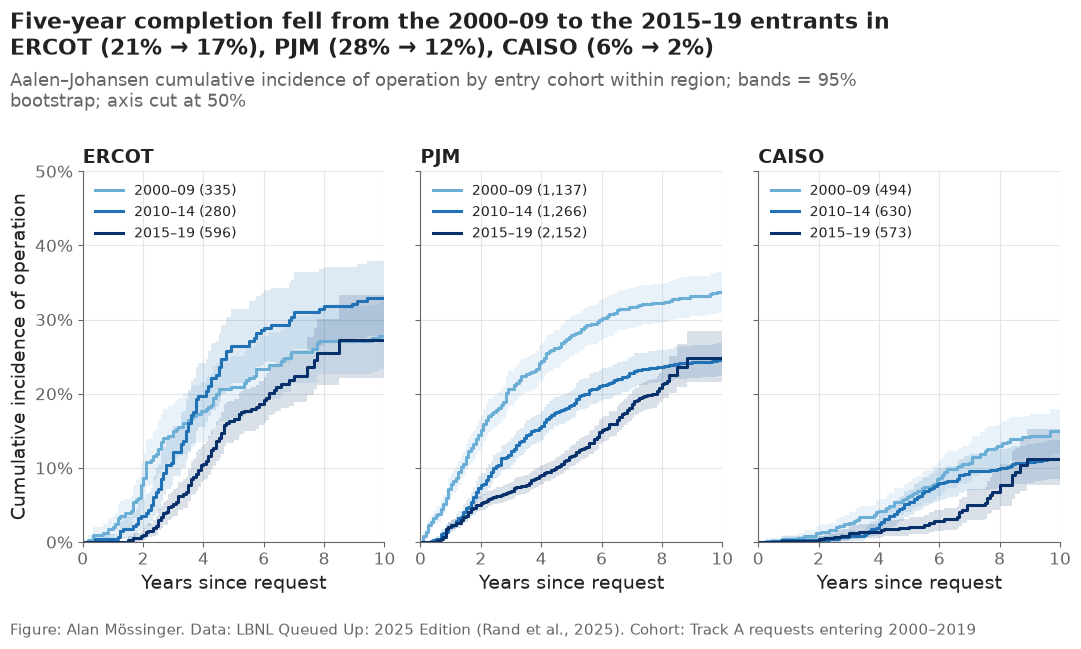

time                                 3.0                  5.0                  7.0
region cohort  n                                                                  
CAISO  2000–09 494      2.6% (1.4%–4.0%)     6.3% (4.0%–8.3%)   10.7% (8.1%–13.4%)
       2010–14 630      0.8% (0.2%–1.6%)     5.4% (3.7%–7.1%)    9.5% (7.1%–11.9%)
       2015–19 573      1.2% (0.3%–2.3%)     2.1% (1.0%–3.3%)     5.0% (3.0%–7.1%)
ERCOT  2000–09 335   14.9% (11.0%–18.8%)  20.9% (16.7%–25.1%)  25.7% (21.5%–30.4%)
       2010–14 280    12.1% (8.9%–15.7%)  26.4% (21.4%–31.4%)  31.1% (26.1%–36.4%)
       2015–19 596      5.2% (3.5%–7.1%)  16.6% (13.8%–19.3%)  22.3% (18.8%–25.9%)
PJM    2000–09 1137  20.7% (18.3%–23.0%)  27.9% (25.2%–30.5%)  31.7% (28.9%–34.3%)
       2010–14 1266  12.2% (10.4%–14.1%)  18.5% (16.7%–20.5%)  22.8% (20.7%–25.1%)
       2015–19 2152     6.9% (5.8%–8.2%)  11.6% (10.2%–13.1%)  18.6% (16.7%–20.5%)

In [13]:
cohort_sample = sample[sample["cohort"].isin(list(COHORT_COLORS))]
by_cohort = survival_tools.curves_by_group(cohort_sample, ["region", "cohort"], TIMES, n_boot=N_BOOT,
                                           seed=SEED + 200)
keep(by_cohort, "region × cohort", ["region", "cohort"])


def cohort_panels(column, ylabel, ymax):
    """Three panels (one per region) of one curve by entry cohort."""
    fig, axes = plt.subplots(1, 3, sharey=True)
    for ax, region in zip(axes, TRACK_A):
        part = by_cohort[by_cohort["region"] == region]
        for cohort, color in COHORT_COLORS.items():
            curve = part[part["cohort"] == cohort]
            if len(curve):
                draw(ax, curve, column, color, f"{cohort} ({curve['n'].iloc[0]:,})")
        ax.set_title(region)
        ax.set_xlim(0, 10)
        ax.set_ylim(0, ymax)
        ax.yaxis.set_major_formatter(lambda y, _: f"{y:.0%}")
        ax.set_xlabel("Years since request")
        ax.legend(loc="upper left", fontsize=10)
    axes[0].set_ylabel(ylabel)
    return fig


fig = cohort_panels("cif_operation", "Cumulative incidence of operation", 0.5)
five_cohort = by_cohort[by_cohort["time"] == 5].set_index(["region", "cohort"])["cif_operation"]
plots.finish(fig,
             "Five-year completion fell from the 2000–09 to the 2015–19 entrants in "
             + ", ".join(f"{r} ({five_cohort[(r, '2000–09')]:.0%} → {five_cohort[(r, '2015–19')]:.0%})"
                         for r in TRACK_A),
             "Aalen–Johansen cumulative incidence of operation by entry cohort within region; bands = 95% "
             "bootstrap; axis cut at 50%",
             "Track A requests entering 2000–2019")
save(fig, "03_03_operation_by_cohort",
     "Cumulative incidence of operation by entry cohort (2000–09, 2010–14, 2015–19) within CAISO, ERCOT and PJM.")
plt.show()
at_horizons(by_cohort, ["region", "cohort"], "cif_operation")

**Reading this.** Five-year completion fell from the 2000–09 to the 2015–19 entrants in all three regions: PJM 27.9% → 18.5% → 11.6%, CAISO 6.3% → 5.4% → 2.1%, and ERCOT 20.9% → 26.4% → 16.6% (ERCOT's 2010–14 cohort did better than both neighbours). In PJM the 2015–19 curve closes part of the gap later (18.6% at seven years against 22.8% for the 2010–14 entrants), so part of the drop is delay rather than failure. A model that pools entry years without a cohort or congestion term would overstate recent projects' chances. The 2015–19 cohort is the one closest to the test set, which is why the temporal split matters.

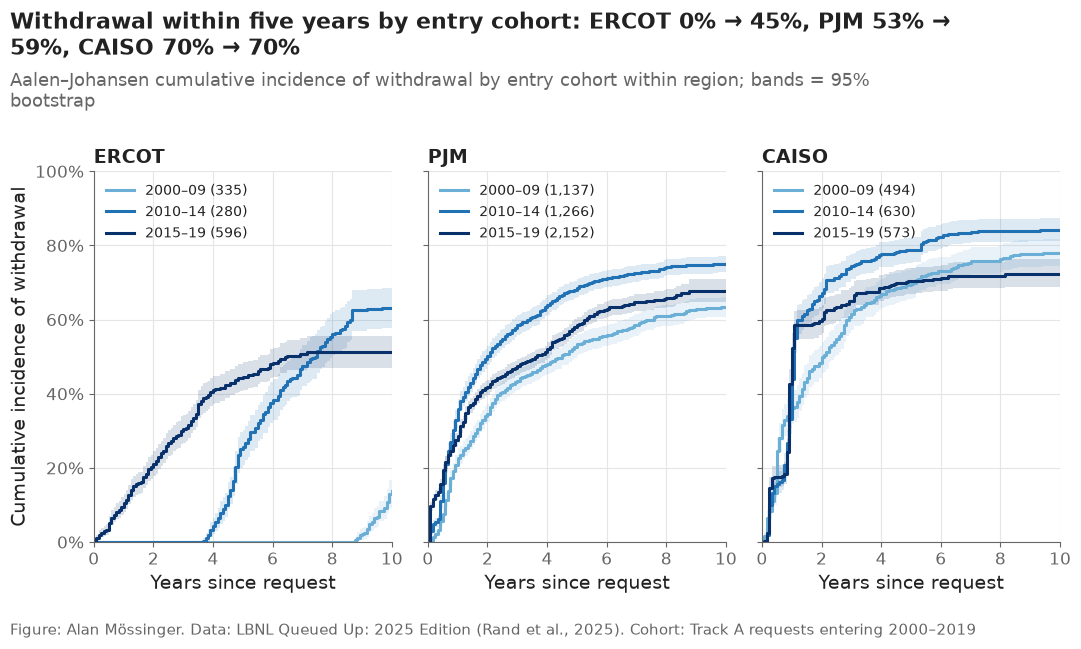

time                                 3.0                  5.0                  7.0
region cohort  n                                                                  
CAISO  2000–09 494   61.5% (57.1%–65.6%)  69.6% (65.7%–73.8%)  75.7% (72.3%–79.7%)
       2010–14 630   74.4% (70.9%–77.8%)  78.7% (75.4%–82.1%)  83.7% (80.9%–86.8%)
       2015–19 573   65.1% (61.6%–68.9%)  70.3% (67.0%–73.9%)  71.9% (68.4%–75.6%)
ERCOT  2000–09 335      0.0% (0.0%–0.0%)     0.0% (0.0%–0.0%)     0.0% (0.0%–0.0%)
       2010–14 280      0.0% (0.0%–0.0%)  25.7% (20.7%–30.4%)  47.5% (42.1%–53.0%)
       2015–19 596   30.4% (26.8%–34.3%)  44.6% (41.1%–48.5%)  50.7% (46.4%–54.9%)
PJM    2000–09 1137  43.4% (41.0%–46.4%)  53.4% (50.6%–56.1%)  58.5% (55.7%–61.4%)
       2010–14 1266  58.5% (55.9%–61.3%)  68.5% (66.2%–70.9%)  72.6% (70.3%–74.6%)
       2015–19 2152  47.4% (45.1%–49.3%)  58.5% (56.4%–60.6%)  64.7% (62.2%–66.8%)

In [14]:
fig = cohort_panels("cif_withdrawal", "Cumulative incidence of withdrawal", 1.0)
five_cohort_wd = by_cohort[by_cohort["time"] == 5].set_index(["region", "cohort"])["cif_withdrawal"]
plots.finish(fig,
             "Withdrawal within five years by entry cohort: "
             + ", ".join(f"{r} {five_cohort_wd[(r, '2000–09')]:.0%} → {five_cohort_wd[(r, '2015–19')]:.0%}"
                         for r in TRACK_A),
             "Aalen–Johansen cumulative incidence of withdrawal by entry cohort within region; bands = 95% bootstrap",
             "Track A requests entering 2000–2019")
save(fig, "03_04_withdrawal_by_cohort",
     "Cumulative incidence of withdrawal by entry cohort within CAISO, ERCOT and PJM.")
plt.show()
at_horizons(by_cohort, ["region", "cohort"], "cif_withdrawal")

**Reading this.** Withdrawal by five years rose from the 2000–09 to the 2010–14 entrants in PJM (53.4% → 68.5%) and CAISO (69.6% → 78.7%), then eased for 2015–19 (58.5% and 70.3%), which may reflect that many 2015–19 projects are still waiting. ERCOT's 0.0% for the 2000–09 cohort at every horizon is impossible on its face — those projects did withdraw — and is the bulk-date artefact again: their withdrawals are all dated 2018-08-29, more than nine years after entry.

## 7. F3 — size and the FERC 20 MW step

Five-year completion by size regime. Only 2000–2019 entrants are used, so every
project has had at least five years in which to finish.

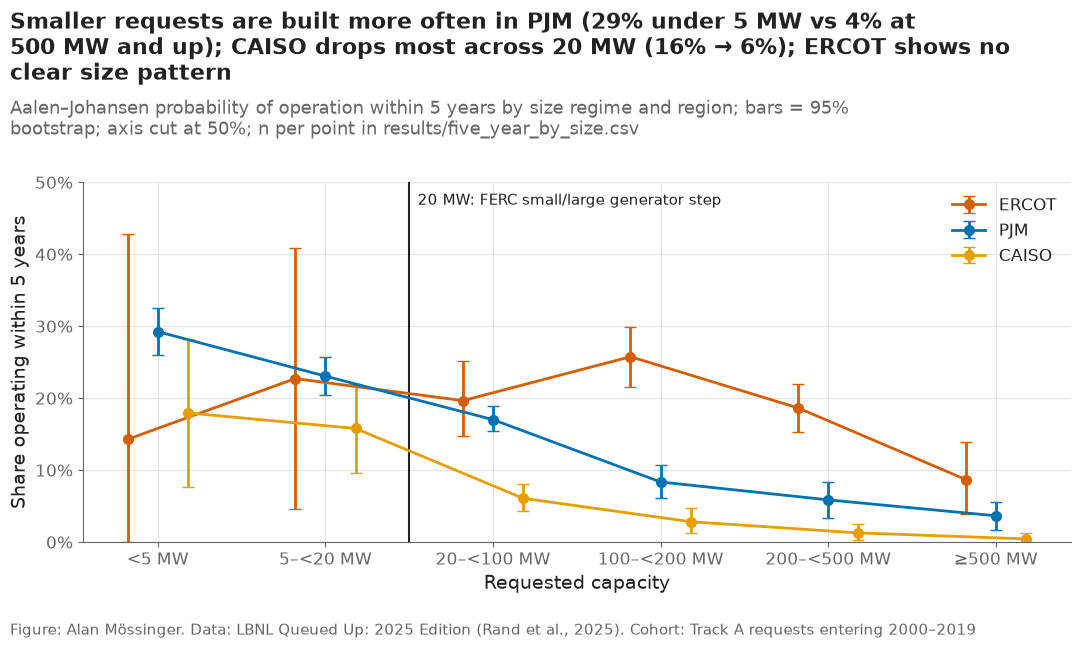

n                    p5              
region       CAISO  ERCOT     PJM  CAISO  ERCOT    PJM
size_regime                                           
100–<200     318.0  361.0   503.0  0.028  0.258  0.083
200–<500     392.0  472.0   358.0  0.013  0.186  0.059
20–<100      608.0  234.0  1493.0  0.061  0.197  0.170
5–<20        114.0   22.0  1110.0  0.158  0.227  0.231
<5            39.0    7.0   735.0  0.179  0.143  0.293
≥500         226.0  115.0   356.0  0.004  0.087  0.037

In [15]:
early = sample[sample["q_year"].between(2000, 2019)]
size_rows = []
for i, ((region, regime), part) in enumerate(early.groupby(["region", "size_regime"], observed=True)):
    fit = survival_tools.aalen_johansen(part["duration_years"], part["event"], [5.0])
    band = survival_tools.bootstrap_bands(part["duration_years"], part["event"], [5.0], n_boot=N_BOOT,
                                          seed=SEED + 300 + i)
    size_rows.append({"region": region, "size_regime": regime, "n": len(part),
                      "p5": fit["cif_operation"].iloc[0], "low": band["cif_operation_low"].iloc[0],
                      "high": band["cif_operation_high"].iloc[0]})
by_size = pd.DataFrame(size_rows)
by_size.to_csv(paths.RESULTS / "five_year_by_size.csv", index=False)

fig, ax = plt.subplots()
x = np.arange(len(config.SIZE_LABELS))
for offset, region in zip([-0.18, 0, 0.18], TRACK_A):
    part = by_size[by_size["region"] == region].set_index("size_regime").reindex(config.SIZE_LABELS)
    ax.errorbar(x + offset, part["p5"], yerr=[part["p5"] - part["low"], part["high"] - part["p5"]],
                color=plots.region_color(region), marker="o", linewidth=2, capsize=4, label=region)
ax.axvline(1.5, color=plots.INK, linewidth=1.5)
ax.text(1.55, 0.485, "20 MW: FERC small/large generator step", fontsize=11, va="top")
ax.set_xticks(x, [f"{label} MW" for label in config.SIZE_LABELS])
ax.set_ylim(0, 0.5)
ax.yaxis.set_major_formatter(lambda y, _: f"{y:.0%}")
ax.set_xlabel("Requested capacity")
ax.set_ylabel("Share operating within 5 years")
ax.legend(loc="upper right")
p5 = by_size.set_index(["region", "size_regime"])["p5"]
plots.finish(fig,
             f"Smaller requests are built more often in PJM ({p5[('PJM', '<5')]:.0%} under 5 MW vs "
             f"{p5[('PJM', '≥500')]:.0%} at 500 MW and up); CAISO drops most across 20 MW "
             f"({p5[('CAISO', '5–<20')]:.0%} → {p5[('CAISO', '20–<100')]:.0%}); ERCOT shows no clear size pattern",
             "Aalen–Johansen probability of operation within 5 years by size regime and region; bars = 95% "
             "bootstrap; axis cut at 50%; n per point in results/five_year_by_size.csv",
             "Track A requests entering 2000–2019")
plots.save_fig(fig, "F3_five_year_by_size",
               "Probability of reaching operation within five years by requested capacity (size regime) for "
               "CAISO, ERCOT and PJM, with the 20 MW FERC small/large generator threshold marked.", NOTEBOOK)
plt.show()
by_size.pivot_table(index="size_regime", columns="region", values=["n", "p5"], observed=True).round(3)

**Reading this.** Size matters most in PJM, where five-year completion falls steadily with size: 29.3% under 5 MW, 23.1% at 5–20 MW, 17.0% at 20–100 MW, 3.7% at 500 MW and above. CAISO shows the clearest drop at the FERC line: 15.8% for 5–20 MW requests against 6.1% for 20–100 MW, although the small CAISO bins hold only 39 and 114 requests. ERCOT shows no size pattern, and its small-request points rest on 7 and 22 projects, hence the wide bars. So the 20 MW step is visible in CAISO, while in PJM size works more like a smooth gradient. Size should therefore enter the models both as `log_mw` and as the regime, so the model can find either shape. Caveat: small requests are older on average in PJM, so part of the gradient may be the cohort effect of 03_03.

## 8. F8 — queue congestion at entry

`features.congestion_at_entry()` counts, for each request, the same-region
requests (and their GW) that entered earlier and had not left by its request
date. Requests are grouped into five equal-sized bins of congestion within each
region; the figure plots five-year completion against each bin's median GW.

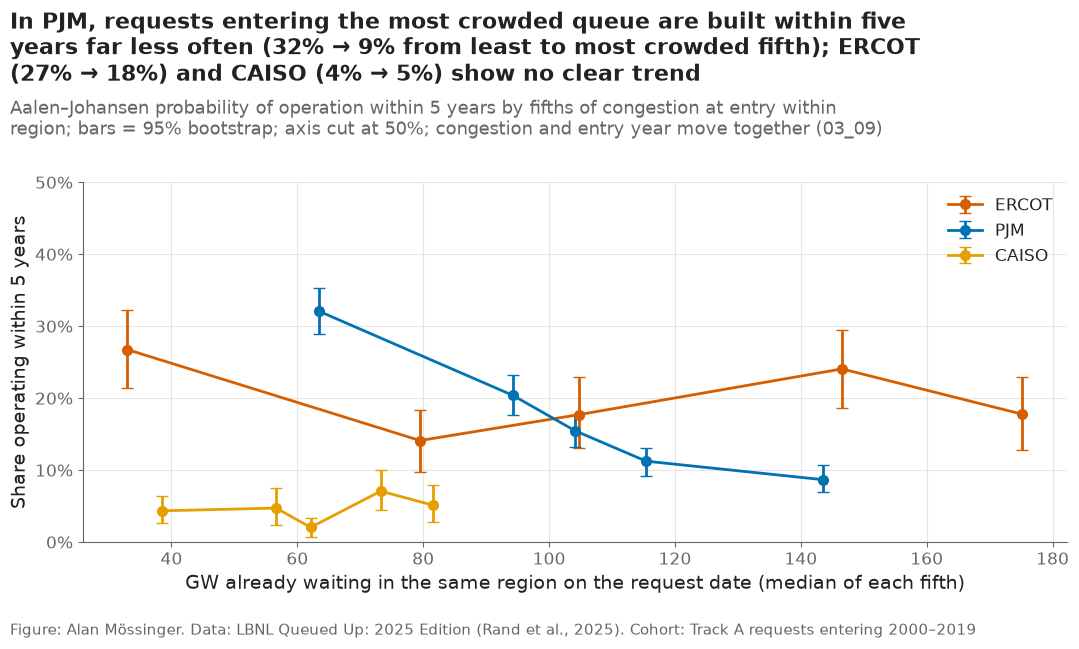

,region,bin,n,gw_median,gw_min,gw_max,p5,low,high
0,CAISO,1,460,38.535,0.550,46.348,0.043,0.026,0.064
1,CAISO,2,254,56.624,46.361,57.131,0.047,0.024,0.075
2,CAISO,3,391,62.114,57.273,66.295,0.020,0.008,0.033
3,CAISO,4,339,73.250,66.492,73.940,0.071,0.044,0.100
4,CAISO,5,253,81.496,74.064,130.481,0.051,0.028,0.079
5,ERCOT,1,243,33.008,0.000,69.463,0.267,0.214,0.323
6,ERCOT,2,248,79.490,69.554,88.121,0.141,0.097,0.184
7,ERCOT,3,237,104.811,88.288,124.061,0.177,0.131,0.230
8,ERCOT,4,241,146.547,124.360,159.469,0.241,0.187,0.295
9,ERCOT,5,242,175.200,159.569,195.396,0.178,0.128,0.229


In [16]:
congestion = features.congestion_at_entry(clean)
early = early.join(congestion)
cong_rows = []
for i, (region, part) in enumerate(early.groupby("region")):
    bins = pd.qcut(part["congestion_gw"], 5, labels=False, duplicates="drop")
    for b, piece in part.groupby(bins):
        fit = survival_tools.aalen_johansen(piece["duration_years"], piece["event"], [5.0])
        band = survival_tools.bootstrap_bands(piece["duration_years"], piece["event"], [5.0], n_boot=N_BOOT,
                                              seed=SEED + 400 + 10 * i + int(b))
        cong_rows.append({"region": region, "bin": int(b) + 1, "n": len(piece),
                          "gw_median": piece["congestion_gw"].median(),
                          "gw_min": piece["congestion_gw"].min(), "gw_max": piece["congestion_gw"].max(),
                          "p5": fit["cif_operation"].iloc[0], "low": band["cif_operation_low"].iloc[0],
                          "high": band["cif_operation_high"].iloc[0]})
by_congestion = pd.DataFrame(cong_rows)
by_congestion.to_csv(paths.RESULTS / "five_year_by_congestion.csv", index=False)

fig, ax = plt.subplots()
for region in TRACK_A:
    part = by_congestion[by_congestion["region"] == region]
    ax.errorbar(part["gw_median"], part["p5"], yerr=[part["p5"] - part["low"], part["high"] - part["p5"]],
                color=plots.region_color(region), marker="o", linewidth=2, capsize=4, label=region)
ax.set_ylim(0, 0.5)
ax.yaxis.set_major_formatter(lambda y, _: f"{y:.0%}")
ax.set_xlabel("GW already waiting in the same region on the request date (median of each fifth)")
ax.set_ylabel("Share operating within 5 years")
ax.legend(loc="upper right")
first_last = by_congestion.groupby("region").agg(first=("p5", "first"), last=("p5", "last"))
plots.finish(fig,
             f"In PJM, requests entering the most crowded queue are built within five years far less often "
             f"({first_last.loc['PJM', 'first']:.0%} → {first_last.loc['PJM', 'last']:.0%} from least to most "
             f"crowded fifth); ERCOT ({first_last.loc['ERCOT', 'first']:.0%} → {first_last.loc['ERCOT', 'last']:.0%}) "
             f"and CAISO ({first_last.loc['CAISO', 'first']:.0%} → {first_last.loc['CAISO', 'last']:.0%}) show no clear trend",
             "Aalen–Johansen probability of operation within 5 years by fifths of congestion at entry within "
             "region; bars = 95% bootstrap; axis cut at 50%; congestion and entry year move together (03_09)",
             "Track A requests entering 2000–2019")
plots.save_fig(fig, "F8_congestion_vs_completion",
               "Probability of reaching operation within five years against the capacity already waiting in "
               "the same region's queue at entry, by fifths of congestion, for CAISO, ERCOT and PJM.", NOTEBOOK)
plt.show()
by_congestion.round(3)

**Reading this.** In PJM, five-year completion falls in every step from the least crowded fifth of entrants (32.1%, median 63 GW already waiting) to the most crowded (8.7%, median 144 GW) — the pattern Johnston, Liu & Yang (2023) describe. ERCOT (26.7% → 17.8%) and CAISO (4.3% → 5.1%) show no consistent trend. This is not yet evidence that congestion *causes* attrition: in PJM congestion rose with time (03_09), so the most crowded fifth is also the most recent, and recent cohorts complete less (03_03). ERCOT's congestion before August 2018 is overstated by the bulk withdrawal date. The models in notebooks 05–06 include entry year and congestion together, which is the fair test of whether congestion adds anything.

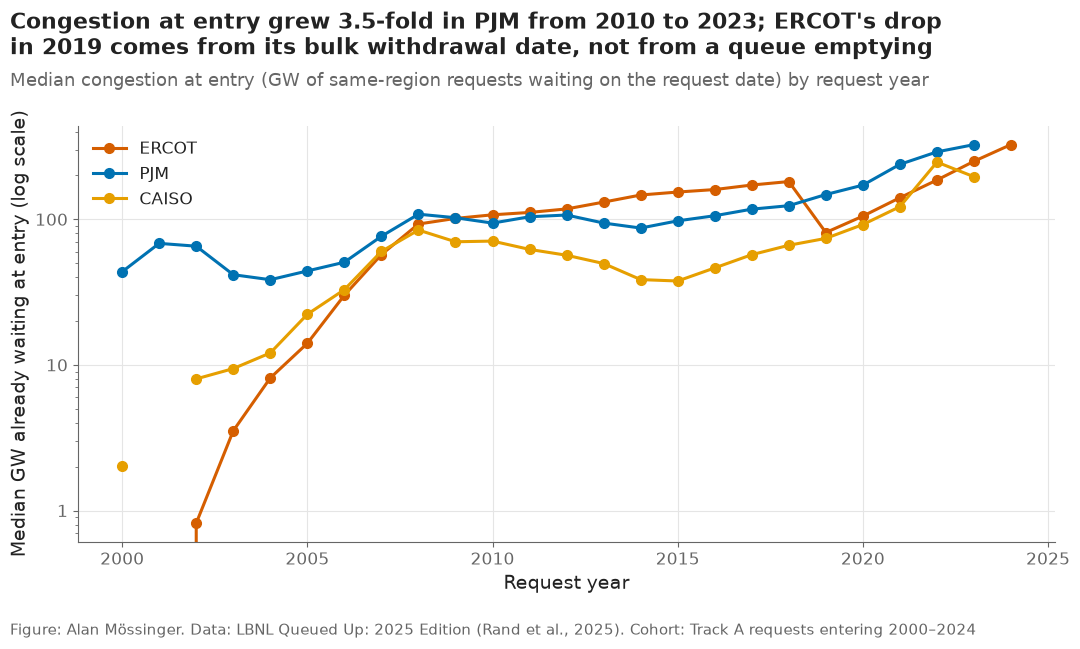

q_year,2005,2010,2015,2019,2020,2022,2023,2024
region,,,,,,,,
CAISO,22.3,70.8,37.7,73.9,92.0,247.0,195.9,NaN
ERCOT,14.1,107.3,153.8,81.1,105.1,186.0,250.2,326.0
PJM,44.2,94.1,97.6,147.9,171.6,290.3,325.6,NaN


In [17]:
track_all = sample.join(congestion)
yearly = track_all[track_all["q_year"].between(2000, 2024)].groupby(["q_year", "region"])["congestion_gw"].median().unstack()
fig, ax = plt.subplots()
for region in TRACK_A:
    ax.plot(yearly.index, yearly[region], color=plots.region_color(region), marker="o", label=region)
ax.set_yscale("log")
ax.yaxis.set_major_formatter(lambda y, _: f"{y:,.0f}" if y >= 1 else f"{y:.1f}")
ax.set_xlabel("Request year")
ax.set_ylabel("Median GW already waiting at entry (log scale)")
ax.legend(loc="upper left")
plots.finish(fig,
             f"Congestion at entry grew {yearly.loc[2023, 'PJM'] / yearly.loc[2010, 'PJM']:.1f}-fold in PJM from "
             "2010 to 2023; ERCOT's drop in 2019 comes from its bulk withdrawal date, not from a queue emptying",
             "Median congestion at entry (GW of same-region requests waiting on the request date) by request year",
             "Track A requests entering 2000–2024")
save(fig, "03_09_congestion_over_time",
     "Median queue congestion at entry (GW waiting in the same region) by request year for CAISO, ERCOT and PJM.")
plt.show()
yearly.loc[[2005, 2010, 2015, 2019, 2020, 2022, 2023, 2024]].round(1).T

**Reading this.** The median PJM request of 2023 joined 325.6 GW already waiting, against 94.1 GW in 2010; CAISO went from 92.0 GW (2020) to 247.0 GW (2022). ERCOT's line drops from 153.8 GW in 2015 to 81.1 GW in 2019. That drop is not a real emptying of the queue: until 2018-08-29 the 441 bulk-dated withdrawals count as waiting, and on that day they all leave at once. Because congestion and entry year move together this closely, the two features will be strongly correlated in the models; the coefficients will need to be read with that in mind.

## 9. Region × technology: the baseline cells

Five-year completion for every region × technology cell of the 2000–2019
entrants. This is the "industry average" the models must beat (notebook 05
fits it on the training cohorts only); cells with fewer than 50 requests are
left blank because their rates are too noisy to use.

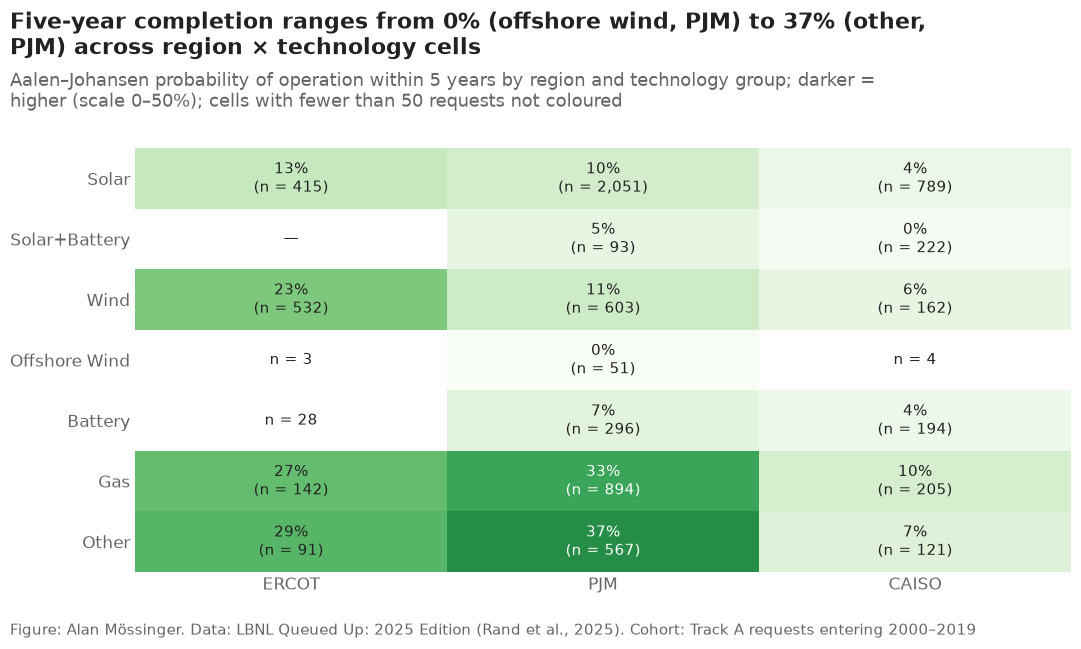

,region,tech_group,n,p5
1,CAISO,Gas,205,0.098
3,CAISO,Other,121,0.074
6,CAISO,Wind,162,0.056
4,CAISO,Solar,789,0.039
0,CAISO,Battery,194,0.036
5,CAISO,Solar+Battery,222,0.005
2,CAISO,Offshore Wind,4,0.000
10,ERCOT,Other,91,0.286
8,ERCOT,Gas,142,0.268
12,ERCOT,Wind,532,0.235


In [18]:
cell_rows = []
for (region, group), part in early.groupby(["region", "tech_group"]):
    fit = survival_tools.aalen_johansen(part["duration_years"], part["event"], [5.0])
    cell_rows.append({"region": region, "tech_group": group, "n": len(part), "p5": fit["cif_operation"].iloc[0]})
cells = pd.DataFrame(cell_rows)
grid = cells.pivot(index="tech_group", columns="region", values="p5").reindex(index=list(config.TECH_COLORS),
                                                                             columns=TRACK_A)
sizes = cells.pivot(index="tech_group", columns="region", values="n").reindex_like(grid)
shown = grid.where(sizes >= 50)

fig, ax = plt.subplots()
ax.imshow(shown.values.astype(float), cmap="Greens", vmin=0, vmax=0.5, aspect="auto")
ax.set_xticks(range(len(TRACK_A)), TRACK_A)
ax.set_yticks(range(len(grid)), grid.index)
ax.grid(False)
ax.tick_params(length=0)
for side in ax.spines.values():
    side.set_visible(False)
for i in range(grid.shape[0]):
    for j in range(grid.shape[1]):
        n = sizes.iat[i, j]
        if pd.isna(n):
            text = "—"
        elif n < 50:
            text = f"n = {int(n)}"
        else:
            text = f"{grid.iat[i, j]:.0%}\n(n = {int(n):,})"
        ax.text(j, i, text, ha="center", va="center", fontsize=11,
                color="white" if (n >= 50 and grid.iat[i, j] > 0.3) else plots.INK)
top = cells[cells["n"] >= 50].sort_values("p5").iloc[-1]
low = cells[cells["n"] >= 50].sort_values("p5").iloc[0]
plots.finish(fig,
             f"Five-year completion ranges from {low['p5']:.0%} ({low['tech_group'].lower()}, {low['region']}) to "
             f"{top['p5']:.0%} ({top['tech_group'].lower()}, {top['region']}) across region × technology cells",
             "Aalen–Johansen probability of operation within 5 years by region and technology group; darker = higher "
             "(scale 0–50%); cells with fewer than 50 requests not coloured",
             "Track A requests entering 2000–2019")
save(fig, "03_05_region_technology_base_rates",
     "Five-year completion probability for each region × technology cell (2000–2019 entrants) — the cells of "
     "the baseline predictor.")
plt.show()
cells.sort_values(["region", "p5"], ascending=[True, False]).round(3)

**Reading this.** Across the region × technology cells of the 2000–2019 entrants, five-year completion runs from 0% (PJM offshore wind, 51 requests) to 37.0% (PJM "Other", 567 requests). The well-populated cells span a wide range within one region: in PJM from 5.4% (solar+battery) to 37.0% ("Other"), with gas at 32.6%. Three cells have fewer than 50 requests (offshore wind in ERCOT and CAISO, batteries in ERCOT) and ERCOT has no solar+battery requests at all; these are left blank, and the baseline in notebook 05 falls back to the regional rate for those, as PLAN.md specifies. This table is the "industry average" a project-level model has to beat.

## 10. Hybrids and service type

Two more entry-time attributes, each in the regions where the field is
informative: hybrid composition (CAISO and PJM; ERCOT records none) and
interconnection service type (CAISO and PJM; ERCOT has no service field).

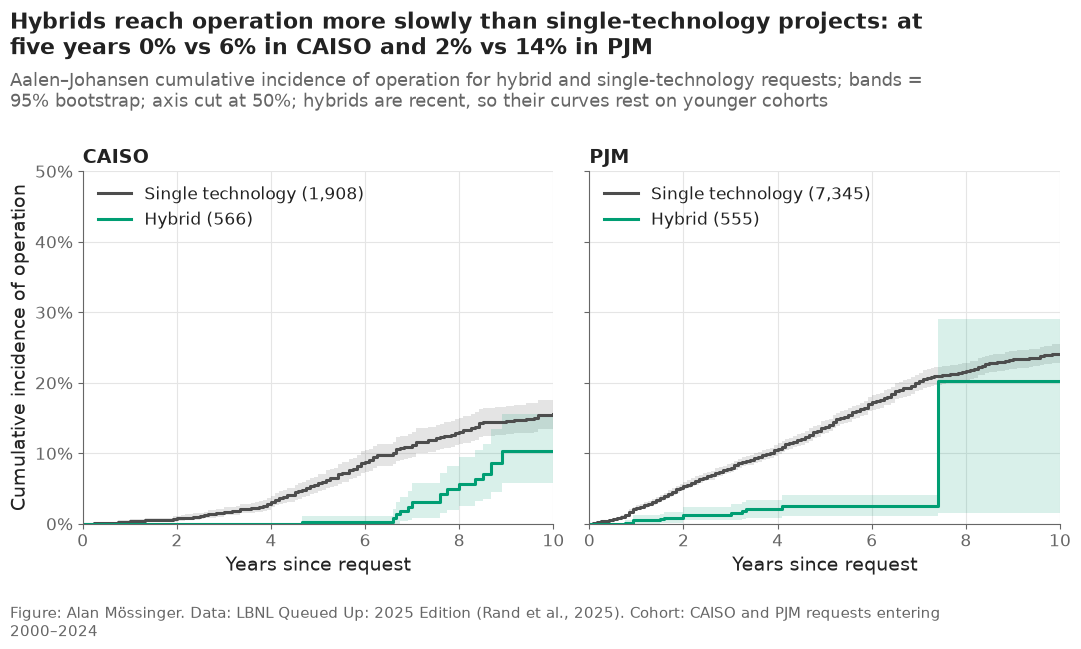

time                                        3.0                  5.0                  7.0
region composition       n                                                               
CAISO  Hybrid            566   0.0% (0.0%–0.0%)     0.3% (0.0%–1.1%)     3.0% (0.8%–5.8%)
       Single technology 1908  1.7% (1.2%–2.3%)     5.8% (4.6%–7.1%)   11.2% (9.5%–13.0%)
PJM    Hybrid            555   1.5% (0.6%–2.8%)     2.5% (1.2%–4.1%)     2.5% (1.2%–4.1%)
       Single technology 7345  8.0% (7.4%–8.6%)  13.8% (12.9%–14.7%)  20.2% (19.0%–21.4%)

In [19]:
hybrid_sample = sample[sample["region"].isin(["CAISO", "PJM"])].assign(
    composition=lambda t: np.where(t["hybrid"], "Hybrid", "Single technology"))
by_hybrid = survival_tools.curves_by_group(hybrid_sample, ["region", "composition"], TIMES, n_boot=N_BOOT,
                                           seed=SEED + 500)
keep(by_hybrid, "region × hybrid", ["region", "composition"])
fig, axes = plt.subplots(1, 2, sharey=True)
for ax, region in zip(axes, ["CAISO", "PJM"]):
    for composition, color in [("Single technology", "#4D4D4D"), ("Hybrid", config.TECH_COLORS["Solar+Battery"])]:
        curve = by_hybrid[(by_hybrid["region"] == region) & (by_hybrid["composition"] == composition)]
        draw(ax, curve, "cif_operation", color, f"{composition} ({curve['n'].iloc[0]:,})")
    ax.set_title(region)
    ax.set_xlim(0, 10)
    ax.set_ylim(0, 0.5)
    ax.yaxis.set_major_formatter(lambda y, _: f"{y:.0%}")
    ax.set_xlabel("Years since request")
    ax.legend(loc="upper left")
axes[0].set_ylabel("Cumulative incidence of operation")
h5 = by_hybrid[by_hybrid["time"] == 5].set_index(["region", "composition"])["cif_operation"]
plots.finish(fig,
             f"Hybrids reach operation more slowly than single-technology projects: at five years "
             f"{h5[('CAISO', 'Hybrid')]:.0%} vs {h5[('CAISO', 'Single technology')]:.0%} in CAISO and "
             f"{h5[('PJM', 'Hybrid')]:.0%} vs {h5[('PJM', 'Single technology')]:.0%} in PJM",
             "Aalen–Johansen cumulative incidence of operation for hybrid and single-technology requests; "
             "bands = 95% bootstrap; axis cut at 50%; hybrids are recent, so their curves rest on younger cohorts",
             "CAISO and PJM requests entering 2000–2024")
save(fig, "03_07_hybrid_vs_single",
     "Cumulative incidence of operation for hybrid and single-technology requests in CAISO and PJM.")
plt.show()
at_horizons(by_hybrid, ["region", "composition"], "cif_operation")

**Reading this.** Hybrids reach operation far more slowly than single-technology projects: at five years 0.3% vs 5.8% in CAISO and 2.5% vs 13.8% in PJM, and the gap is still there at seven years (3.0% vs 11.2%; 2.5% vs 20.2%). Most hybrids entered after 2018, so their curves rest on recent cohorts with short follow-up, and the comparison partly mixes "hybrid" with "recent". The models separate the two by including both the hybrid flag and the entry year.

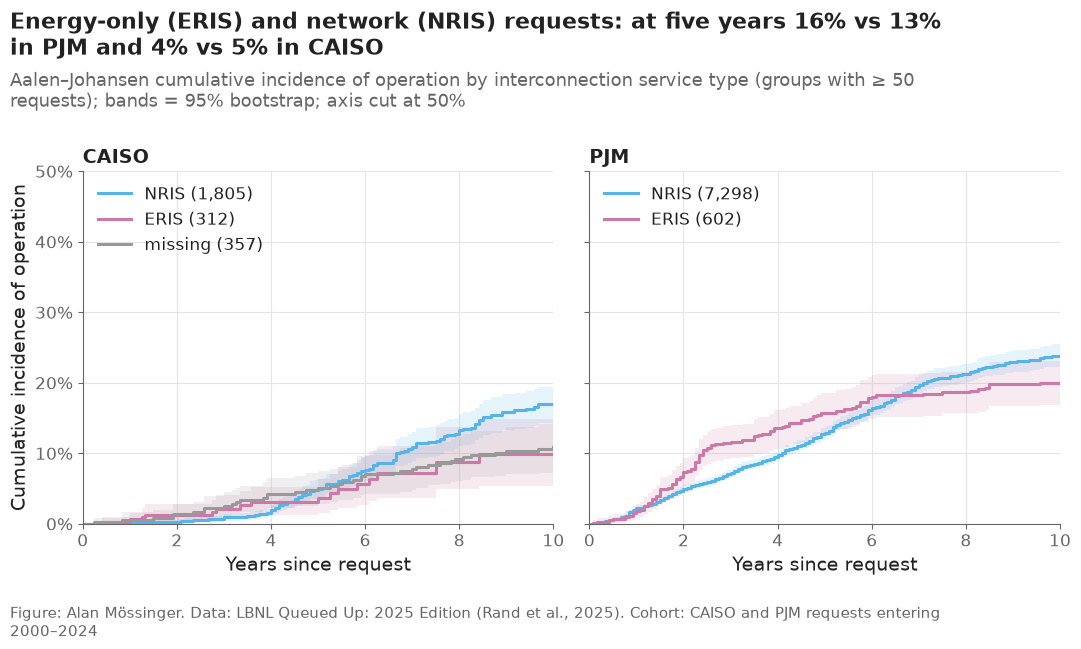

time                                3.0                  5.0                  7.0
region service n                                                                 
CAISO  ERIS    312     2.2% (0.6%–4.1%)     3.7% (1.5%–6.4%)    7.2% (3.7%–11.1%)
       NRIS    1805    0.9% (0.5%–1.4%)     5.0% (3.8%–6.4%)   10.9% (8.9%–13.1%)
       missing 357     2.5% (1.1%–4.5%)     5.0% (2.8%–7.6%)    7.8% (4.8%–10.9%)
PJM    ERIS    602   11.7% (9.3%–14.0%)  15.7% (12.8%–18.5%)  18.2% (15.2%–21.3%)
       NRIS    7298    7.2% (6.6%–7.8%)  12.9% (12.0%–13.8%)  19.8% (18.5%–21.2%)

In [20]:
service_colors = {"NRIS": "#56B4E9", "ERIS": "#CC79A7", "NRIS/ERIS": "#009E73", "missing": "#999999"}
service_sample = sample[sample["region"].isin(["CAISO", "PJM"]) & sample["service"].isin(list(service_colors))]
by_service = survival_tools.curves_by_group(service_sample, ["region", "service"], TIMES, n_boot=N_BOOT,
                                            seed=SEED + 600, min_n=50)
keep(by_service, "region × service", ["region", "service"])
fig, axes = plt.subplots(1, 2, sharey=True)
for ax, region in zip(axes, ["CAISO", "PJM"]):
    for service, color in service_colors.items():
        curve = by_service[(by_service["region"] == region) & (by_service["service"] == service)]
        if len(curve):
            draw(ax, curve, "cif_operation", color, f"{service} ({curve['n'].iloc[0]:,})")
    ax.set_title(region)
    ax.set_xlim(0, 10)
    ax.set_ylim(0, 0.5)
    ax.yaxis.set_major_formatter(lambda y, _: f"{y:.0%}")
    ax.set_xlabel("Years since request")
    ax.legend(loc="upper left")
axes[0].set_ylabel("Cumulative incidence of operation")
s5 = by_service[by_service["time"] == 5].set_index(["region", "service"])["cif_operation"]
plots.finish(fig,
             f"Energy-only (ERIS) and network (NRIS) requests: at five years {s5.get(('PJM', 'ERIS'), np.nan):.0%} vs "
             f"{s5.get(('PJM', 'NRIS'), np.nan):.0%} in PJM and {s5.get(('CAISO', 'ERIS'), np.nan):.0%} vs "
             f"{s5.get(('CAISO', 'NRIS'), np.nan):.0%} in CAISO",
             "Aalen–Johansen cumulative incidence of operation by interconnection service type (groups with ≥ 50 "
             "requests); bands = 95% bootstrap; axis cut at 50%",
             "CAISO and PJM requests entering 2000–2024")
save(fig, "03_08_service_type",
     "Cumulative incidence of operation by interconnection service type (ERIS, NRIS) in CAISO and PJM.")
plt.show()
at_horizons(by_service, ["region", "service"], "cif_operation")

**Reading this.** Energy-only (ERIS) and network (NRIS) requests reach operation at similar rates: at five years 15.7% vs 12.9% in PJM and 3.7% vs 5.0% in CAISO, with overlapping bands in CAISO, and by seven years PJM's two curves meet (18.2% vs 19.8%). This agrees with LBNL's "ERIS ≈ NRIS" in direction. Requests with no service type in CAISO (n = 357) look like NRIS. Service type is therefore unlikely to be a strong feature, and in ERCOT it is not recorded at all.

## 11. External benchmarks: does the clean file reproduce LBNL's summaries?

Five published LBNL summaries, each recomputed from the clean table with the
same definition (`src/benchmarks.py`). LBNL's summaries use 7 ISOs and 32
non-ISO areas and partly non-public data, so small gaps are expected; large
ones would point at a problem in the data or the cleaning.

In [21]:
lbnl_file = get_lbnl.download()
parts = []
for sheet, label, column, groups in [("22. Comp. Rate Gen Type", "Type", "type_clean", None),
                                     ("23. Comp. Rate Region", "Region", "region", None)]:
    theirs = benchmarks.lbnl_completion(lbnl_file, sheet, label)
    mine = benchmarks.my_completion(clean, column, theirs["group"].tolist())
    both = theirs.merge(mine, on="group", suffixes=("_lbnl", "_mine"))
    for measure in ["by_count", "by_capacity"]:
        parts.append(pd.DataFrame({"benchmark": f"completion rate {measure.replace('_', ' ')} ({label.lower()})",
                                   "group": both["group"], "lbnl": both[f"{measure}_lbnl"],
                                   "mine": both[f"{measure}_mine"]}))
post_ia_mine, n_signed = benchmarks.my_post_ia(clean)
post_ia = pd.concat([benchmarks.lbnl_post_ia(lbnl_file), post_ia_mine], axis=1)
parts.append(pd.DataFrame({"benchmark": "status after IA (IA signed 2000–2021)", "group": post_ia.index,
                           "lbnl": post_ia["lbnl"], "mine": post_ia["mine"]}))
size = pd.concat([benchmarks.lbnl_ir_to_cod_by_size(lbnl_file).rename("lbnl"),
                  benchmarks.my_ir_to_cod_by_size(clean).rename("mine")], axis=1)
parts.append(pd.DataFrame({"benchmark": "median months request→operation (COD 2018–2024)",
                           "group": size.index.astype(str), "lbnl": size["lbnl"], "mine": size["mine"]}))
service = pd.concat([benchmarks.lbnl_ir_to_ia_by_service(lbnl_file).rename("lbnl"),
                     benchmarks.my_ir_to_ia_by_service(clean).rename("mine")], axis=1).dropna()
parts.append(pd.DataFrame({"benchmark": "median months request→IA (IA 2010–2024)",
                           "group": service.index, "lbnl": service["lbnl"], "mine": service["mine"]}))
bench = pd.concat(parts, ignore_index=True)
bench["difference"] = bench["mine"] - bench["lbnl"]
bench.to_csv(paths.RESULTS / "benchmarks.csv", index=False)
print("Requests with an IA signed 2000–2021 in the clean file:", n_signed)
bench.round(3)

Requests with an IA signed 2000–2021 in the clean file: 1505


,benchmark,group,lbnl,mine,difference
0,completion rate by count (type),Battery,0.082,0.082,0.0
1,completion rate by count (type),Gas,0.299,0.297,-0.002
2,completion rate by count (type),Geothermal,0.138,0.136,-0.001
3,completion rate by count (type),Hydro,0.455,0.458,0.003
4,completion rate by count (type),Nuclear,0.578,0.59,0.012
5,completion rate by count (type),Solar,0.134,0.133,-0.0
6,completion rate by count (type),Solar+Battery,0.091,0.088,-0.002
7,completion rate by count (type),Wind,0.196,0.194,-0.001
8,completion rate by capacity (type),Battery,0.053,0.056,0.002
9,completion rate by capacity (type),Gas,0.165,0.164,-0.001


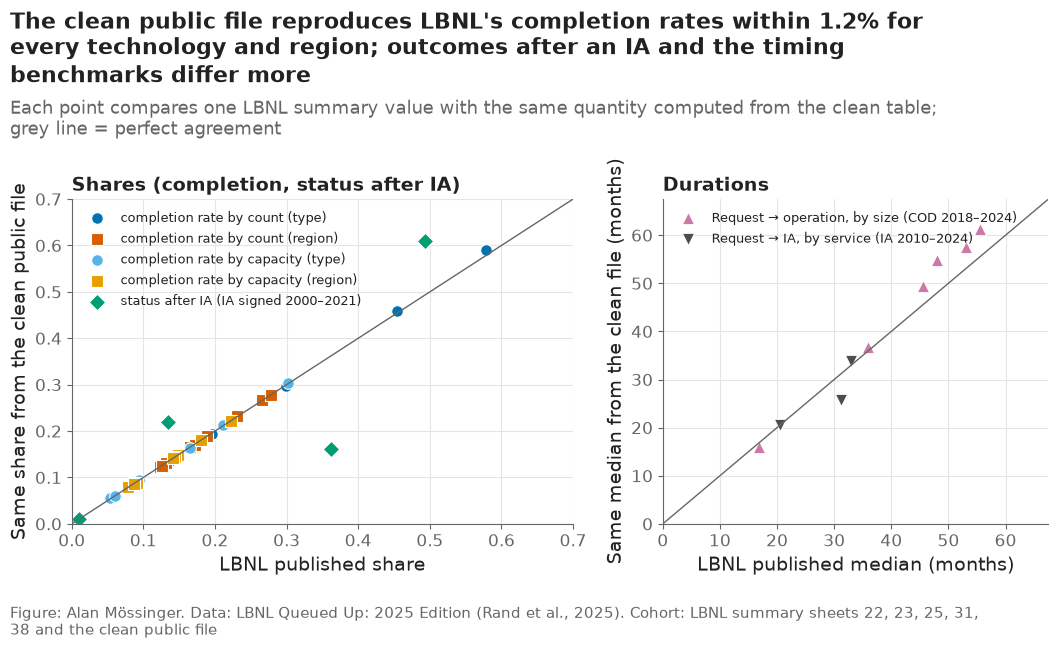

,count,median,<lambda_0>
benchmark,,,
completion rate by capacity (region),9,-0.0,0.002
completion rate by capacity (type),8,-0.001,0.002
completion rate by count (region),9,0.0,0.003
completion rate by count (type),8,-0.001,0.012
median months request→IA (IA 2010–2024),3,0.002,5.418
median months request→operation (COD 2018–2024),6,4.201,6.739
status after IA (IA signed 2000–2021),4,0.043,0.201


In [22]:
families = {"completion rate by count (type)": ("o", "#0072B2"), "completion rate by count (region)": ("s", "#D55E00"),
            "completion rate by capacity (type)": ("o", "#56B4E9"), "completion rate by capacity (region)": ("s", "#E69F00"),
            "status after IA (IA signed 2000–2021)": ("D", "#009E73")}
fig, axes = plt.subplots(1, 2, gridspec_kw={"width_ratios": [1.3, 1]})
for name, (marker, color) in families.items():
    part = bench[bench["benchmark"] == name]
    axes[0].scatter(part["lbnl"], part["mine"], marker=marker, color=color, s=70, label=name,
                    edgecolors="white", linewidths=0.8)
axes[0].plot([0, 0.7], [0, 0.7], color=plots.MUTED, linewidth=1)
axes[0].set_xlim(0, 0.7)
axes[0].set_ylim(0, 0.7)
axes[0].set_xlabel("LBNL published share")
axes[0].set_ylabel("Same share from the clean public file")
axes[0].set_title("Shares (completion, status after IA)")
axes[0].legend(loc="upper left", fontsize=9.5)
for name, (marker, color, label) in {
        "median months request→operation (COD 2018–2024)": ("^", "#CC79A7", "Request → operation, by size (COD 2018–2024)"),
        "median months request→IA (IA 2010–2024)": ("v", "#4D4D4D", "Request → IA, by service (IA 2010–2024)")}.items():
    part = bench[bench["benchmark"] == name]
    axes[1].scatter(part["lbnl"], part["mine"], marker=marker, color=color, s=80, label=label,
                    edgecolors="white", linewidths=0.8)
top = float(bench.loc[bench["benchmark"].str.startswith("median"), ["lbnl", "mine"]].max().max()) * 1.1
axes[1].plot([0, top], [0, top], color=plots.MUTED, linewidth=1)
axes[1].set_xlim(0, top)
axes[1].set_ylim(0, top)
axes[1].set_xlabel("LBNL published median (months)")
axes[1].set_ylabel("Same median from the clean file (months)")
axes[1].set_title("Durations")
axes[1].legend(loc="upper left", fontsize=9.5)
completion = bench[bench["benchmark"].str.startswith("completion")]
plots.finish(fig,
             f"The clean public file reproduces LBNL's completion rates within {completion['difference'].abs().max():.1%} "
             "for every technology and region; outcomes after an IA and the timing benchmarks differ more",
             "Each point compares one LBNL summary value with the same quantity computed from the clean table; "
             "grey line = perfect agreement",
             "LBNL summary sheets 22, 23, 25, 31, 38 and the clean public file")
save(fig, "03_06_benchmarks",
     "LBNL's published completion rates, post-IA outcomes and median durations against the same quantities "
     "computed from the clean public file.")
plt.show()
bench.groupby("benchmark")["difference"].agg(["count", "median", lambda d: d.abs().max()]).round(3)

**Reading this.** The clean public file reproduces LBNL's published completion rates almost exactly: for every technology and every region, by count and by capacity, the gap is at most 1.2 points (Nuclear by count) and the typical gap is 0.1 points. This is the strongest evidence so far that the data and the cleaning are sound. Two other benchmarks do not reproduce, for reasons the public file explains. Status after an IA (IAs signed 2000–2021): the public file has IA dates for only 1,505 such requests and they are concentrated in a few regions, so its withdrawn share (16.1%) is far below LBNL's 36.2% — LBNL's figure uses IA data that the public file does not carry. Timing: median months from request to operation are 0.9–6.7 months longer here for requests of 5 MW and above, and the request-to-IA medians match for ERCOT (20.5 months) and NRIS (33.8 vs 33.0) but not for ERIS (25.8 vs 31.2). I cite LBNL's 36% post-IA figure from LBNL, not from this file.

## 12. Six drivers of five-year completion in one panel (F19)

Sections 5, 7, 8 and 10 each showed one attribute at a time, on different cohorts and with censoring-corrected curves. An energy company deciding what to enter needs the drivers side by side, on one cohort, with one estimator. This section takes the 2010–2019 entrants, every one of which has five full years of follow-up by the censor date (the cell asserts it), and measures the plain share operating within five years with a 95% Wilson interval, within each region, by: size regime (FERC's 20 MW step), technology, the regional queue at entry (GW already waiting, cut into fifths within the region), crowding in the same county (other requests in the two years before entry), interconnection service, and the first event after entry, an executed interconnection agreement within two years of the request (the 2025 file's dated agreements; notebook 14 adds the 2026 edition's). Earlier cohorts are left out because ERCOT's withdrawals are dated only from about 2010 (section 2). The helpers are in `src/drivers.py`.

In [23]:
drv = drivers.five_year_cohort(track_all.rename(columns={"tech_group": "tech"}))
drv["county_crowding"] = drivers.poi_crowding(drv, key="fips_codes")
drv["crowding_bin"] = pd.cut(drv["county_crowding"], [-0.5, 0.5, 2.5, 5.5, 10.5, np.inf], labels=["0", "1–2", "3–5", "6–10", "11+"])
drv["queue_quintile"] = drivers.congestion_quintile(drv)
drv["service_type"] = drv["service"].fillna("not recorded").replace({"missing": "not recorded"})
inside = drv["ia_date"].notna() & (drv["ia_date"] >= drv["q_date"]) & (drv["exit_date"].isna() | (drv["ia_date"] <= drv["exit_date"]))
ia_years = ((drv["ia_date"] - drv["q_date"]).dt.days / config.DAYS_PER_YEAR).where(inside)
drv["agreement"] = np.where(ia_years <= 2, "signed within 2 years", np.where(inside, "signed later", "not dated"))

DRIVERS = [("size_regime", "Size at entry (MW)"), ("tech", "Technology"), ("queue_quintile", "Regional queue at entry (fifth)"),
           ("crowding_bin", "Same-county requests, prior 2 years"), ("service_type", "Service type"),
           ("agreement", "Agreement (2025 file)")]
driver_rates = pd.concat([drivers.rate_by(drv, column, driver=label) for column, label in DRIVERS], ignore_index=True)
driver_rates["level"] = driver_rates["level"].astype(str)
driver_rates.to_csv(paths.RESULTS / "drivers_5yr.csv", index=False)
base = drv.groupby("region")["built"].agg(requests="size", built="sum", rate="mean")
print(f"cohort: {len(drv):,} entrants of {drivers.COHORT_YEARS[0]}–{drivers.COHORT_YEARS[1]}; five-year completion {drv['built'].mean():.1%}")
print(base.round(3))
print(driver_rates[driver_rates["driver"].isin(["Size at entry (MW)", "Agreement (2025 file)"]) & ~driver_rates["thin"]]
      .pivot(index=["driver", "level"], columns="region", values="rate").round(3))

cohort: 5,497 entrants of 2010–2019; five-year completion 12.8%
        requests  built   rate
region                        
CAISO       1203     46  0.038
ERCOT        876    173  0.197
PJM         3418    484  0.142
region                                       CAISO  ERCOT    PJM
driver                level                                     
Agreement (2025 file) not dated              0.015  0.008  0.142
                      signed later           0.106  0.178    NaN
                      signed within 2 years    NaN  0.633    NaN
Size at entry (MW)    100–<200               0.023  0.234  0.059
                      200–<500               0.007  0.189  0.040
                      20–<100                0.051  0.188  0.136
                      5–<20                  0.112    NaN  0.160
                      <5                     0.139    NaN  0.244
                      ≥500                   0.008  0.109  0.044


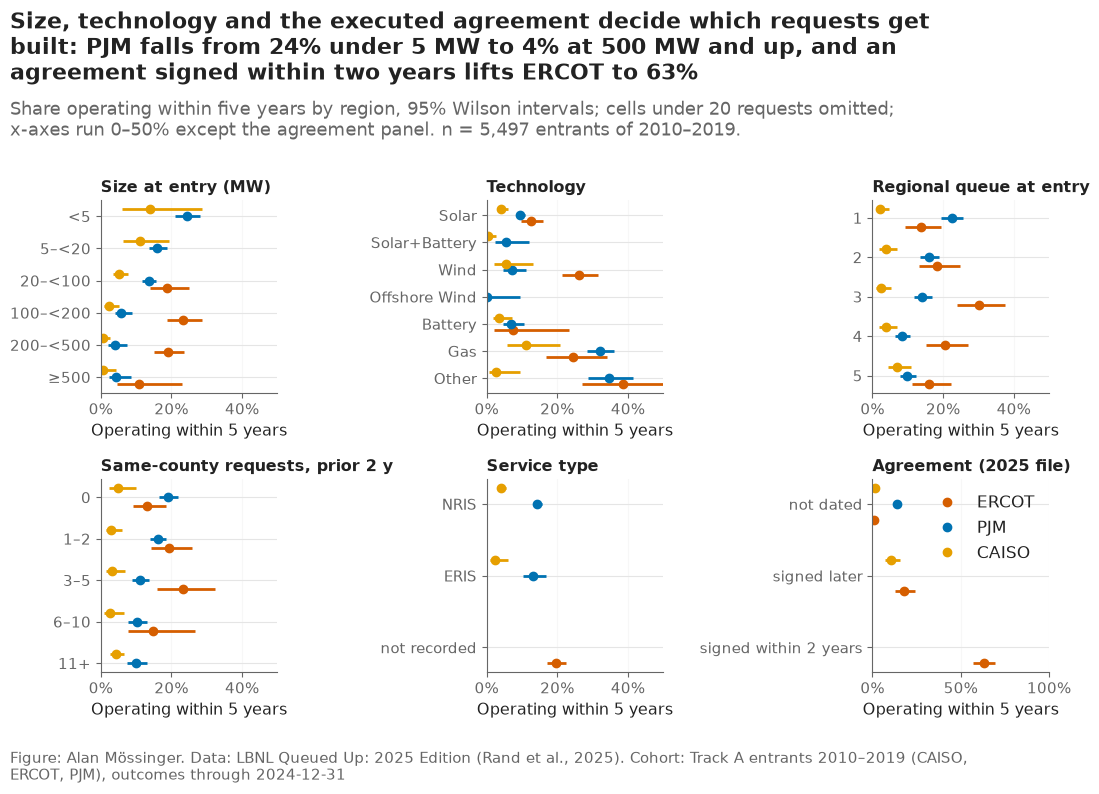

In [24]:
LEVEL_ORDER = {"size_regime": config.SIZE_LABELS, "tech": list(config.TECH_COLORS), "queue_quintile": ["1", "2", "3", "4", "5"],
               "crowding_bin": ["0", "1–2", "3–5", "6–10", "11+"], "service_type": ["NRIS", "ERIS", "not recorded"],
               "agreement": ["not dated", "signed later", "signed within 2 years"]}
TITLES = {"Regional queue at entry (fifth)": "Regional queue at entry", "Same-county requests, prior 2 years": "Same-county requests, prior 2 y"}
fig, axes = plt.subplots(2, 3, figsize=(11, 8))
offsets = {"ERCOT": 0.22, "PJM": 0.0, "CAISO": -0.22}
for ax, (column, label) in zip(axes.ravel(), DRIVERS):
    present = set(driver_rates.loc[driver_rates["driver"] == label, "level"])
    levels = [lv for lv in LEVEL_ORDER[column] if lv in present]
    sub = driver_rates[(driver_rates["driver"] == label) & ~driver_rates["thin"]]
    for region in ["ERCOT", "PJM", "CAISO"]:
        r = sub[sub["region"] == region].set_index("level").reindex(levels)
        y = np.arange(len(levels)) + offsets[region]
        ax.hlines(y, r["low"], r["high"], color=plots.region_color(region), lw=2)
        ax.plot(r["rate"], y, "o", color=plots.region_color(region), ms=6, label=region)
    ax.set_yticks(np.arange(len(levels)))
    ax.set_yticklabels(levels, fontsize=11)
    ax.invert_yaxis()
    ax.set_title(TITLES.get(label, label), fontsize=11.5, loc="left")
    ax.set_xlim(0, 1 if column == "agreement" else 0.5)
    ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
    ax.set_xlabel("Operating within 5 years", fontsize=11.5)
    ax.tick_params(axis="x", labelsize=11)
    ax.grid(axis="x", alpha=0.3)
axes[1, 2].legend(loc="upper right", frameon=False)
ag = driver_rates[driver_rates["driver"] == "Agreement (2025 file)"].set_index(["region", "level"])["rate"]
sz = driver_rates[driver_rates["driver"] == "Size at entry (MW)"].set_index(["region", "level"])["rate"]
plots.finish(fig,
             f"Size, technology and the executed agreement decide which requests get built: PJM falls from {sz[('PJM', '<5')]:.0%} under 5 MW to "
             f"{sz[('PJM', '≥500')]:.0%} at 500 MW and up, and an agreement signed within two years lifts ERCOT to {ag[('ERCOT', 'signed within 2 years')]:.0%}",
             f"Share operating within five years by region, 95% Wilson intervals; cells under 20 requests omitted; x-axes run 0–50% except the agreement panel. n = {len(drv):,} entrants of 2010–2019.",
             "Track A entrants 2010–2019 (CAISO, ERCOT, PJM), outcomes through 2024-12-31")
plots.save_fig(fig, "F19_drivers", "Five-year completion by six drivers (size, technology, regional queue at entry, county crowding, service type, executed agreement within two years) within each region, 2010–2019 entrants, with 95% Wilson intervals.", NOTEBOOK)
plt.show()

**Reading this.** 12.8% of the 5,497 requests were operating five years after they asked to connect: 3.8% in CAISO, 14.2% in PJM, 19.7% in ERCOT, the base rates every panel is read against. Three things decide the fate of a request at entry, and one just after it.

- **Size.** In PJM, five-year completion falls from 24% under 5 MW to 4% at 200 MW and more; in CAISO from 14% to about 1%. ERCOT is the exception: 19–23% from 20 MW up to 500 MW, 11% beyond. A company choosing in PJM between one 300 MW request and three 100 MW requests is choosing between a 4% and a 6% chance per request, and between one draw and three.
- **Technology.** Gas reaches operation at 32% in PJM and 25% in ERCOT; solar at 9% and 13%; batteries at 4–7% everywhere; of the 37 PJM offshore wind requests none operated within five years. Solar paired with storage runs below stand-alone solar in CAISO (0.5% against 4%) and PJM (5% against 9%); hybrids are young and sit in the queue (section 10).
- **The regional queue at entry.** PJM's completion falls from 22% in its quietest fifth of entry dates to 10% in its most crowded fifth. ERCOT and CAISO show no such gradient. Because the GW waiting rises with calendar time (03_09), this panel partly shows the slowdown of later cohorts, not only congestion.
- **County crowding** matters in PJM (19% with no earlier neighbour against 10% with eleven or more) and not elsewhere. **Service type** barely moves the raw rate (PJM 14% NRIS against 13% ERIS; ERCOT does not record it); the adjusted hazard ratio of 0.70 in notebook 05 is what remains after size and technology are held fixed.
- **The agreement.** Where the 2025 file dates an executed interconnection agreement within two years of the request, 63% of ERCOT's 218 such requests were operating within five years; where none is dated, 0.8% of 484. CAISO's 19 early agreements are too few to show, and its 189 later ones ran at 11% against 1.5% undated. PJM's agreements are dated for under 3% of its requests (notebook 13), so its single cell is its base rate, not a signal. For an energy company, the agreement is the one observable event that separates a 1-in-100 request from a 2-in-3 one; notebook 14 builds the milestone model on it.

## 13. Where and when requests die (F20)

Three views of the same cohort, each answering a question the company asks about a request it already holds. Left: the annual hazard of withdrawal and of operation by year in the queue, by region (year k covers the k-th year after the request; a request counts in year k if it was still waiting at the start of the year and watched through it). Middle: the study stage a withdrawn request had reached when it left, from LBNL's phase field. Right: among the requests still in the queue after s years, the share that reaches operation within the next three years, the "hold value" of having survived; at s = 2 this is the quantity the landmark model of notebook 14 predicts.

In [25]:
hazards = drivers.annual_hazards(drv)
hazards.to_csv(paths.RESULTS / "hazards_by_queue_year.csv", index=False)
withdrawn = drv[drv["event"] == 2].copy()
withdrawn["stage"] = drivers.stage_at_exit(withdrawn["IA_status_clean"])
exit_stage = withdrawn.groupby(["region", "stage"], observed=False).size().rename("withdrawals").reset_index()
exit_stage["share"] = exit_stage["withdrawals"] / exit_stage.groupby("region")["withdrawals"].transform("sum")
exit_stage.to_csv(paths.RESULTS / "exit_stage.csv", index=False)
exit_timing = (withdrawn.groupby(["region", "stage"], observed=True)["duration_years"]
               .agg(n="size", median_years="median", q25=lambda s: s.quantile(0.25), q75=lambda s: s.quantile(0.75)).reset_index())
exit_timing.to_csv(paths.RESULTS / "exit_timing.csv", index=False)
rows = []
for region, g in drv.groupby("region"):
    for s in [0, 1, 2]:
        alive = g[(g["duration_years"] > s) | (g["event"] == 0)]
        built = int(((alive["event"] == 1) & (alive["duration_years"] <= s + 3)).sum())  # operates within the next three years
        low, high = drivers.wilson(built, len(alive))
        rows.append({"region": region, "survived_years": s, "n": len(alive), "built": built, "rate": built / len(alive),
                     "low": float(low), "high": float(high)})
given_survival = pd.DataFrame(rows)
given_survival.to_csv(paths.RESULTS / "completion_given_survival.csv", index=False)
print(hazards.pivot(index="year_in_queue", columns="region", values=["h_withdrawal", "h_operation"]).round(3))
print(exit_stage.pivot(index="region", columns="stage", values="share").round(3))
print(exit_timing.pivot(index="region", columns="stage", values="median_years").round(2))
print(given_survival.pivot(index="survived_years", columns="region", values="rate").round(3))

              h_withdrawal               h_operation              
region               CAISO  ERCOT    PJM       CAISO  ERCOT    PJM
year_in_queue                                                     
1                    0.480  0.072  0.313       0.002  0.001  0.022
2                    0.307  0.078  0.205       0.002  0.018  0.059
3                    0.172  0.075  0.135       0.019  0.067  0.055
4                    0.112  0.119  0.123       0.032  0.084  0.067
5                    0.060  0.163  0.181       0.077  0.110  0.082
6                    0.125  0.190  0.200       0.093  0.069  0.161
7                    0.078  0.203  0.123       0.128  0.089  0.196
stage   Feasibility study  System impact study  Facilities study  Study (phase unknown)  Agreement executed  Unknown
region                                                                                                              
CAISO               0.139                0.820             0.000                  0.014         

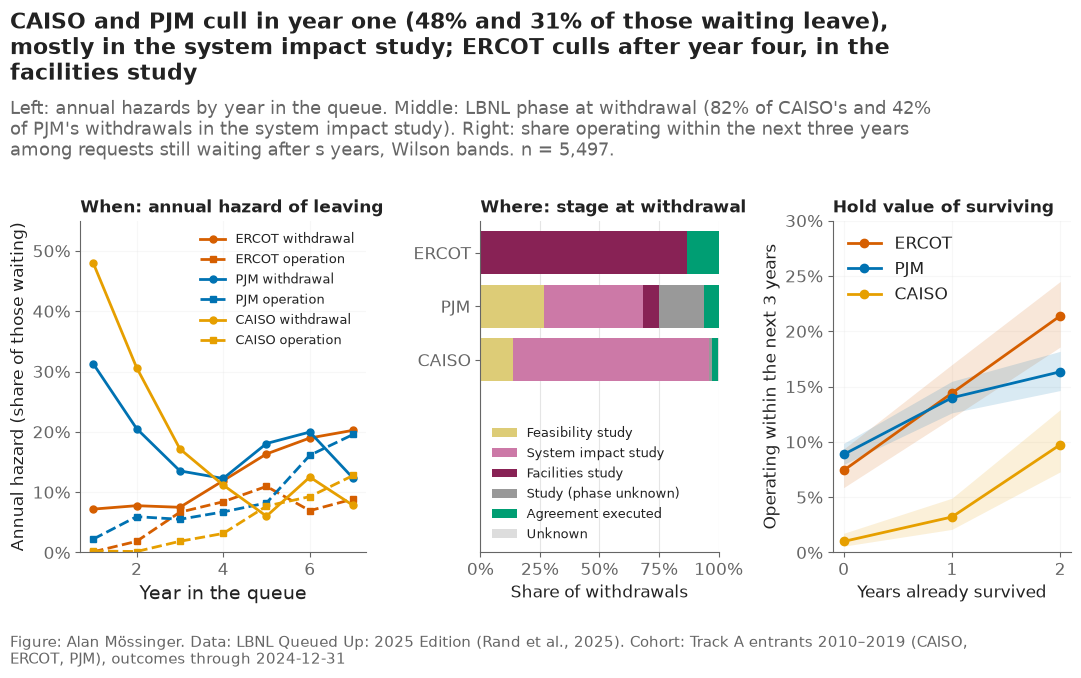

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(11, 6.8), gridspec_kw={"width_ratios": [1.2, 1, 1]})
ax = axes[0]
for region in ["ERCOT", "PJM", "CAISO"]:
    h = hazards[hazards["region"] == region]
    ax.plot(h["year_in_queue"], h["h_withdrawal"], "-o", color=plots.region_color(region), lw=2, ms=5, label=f"{region} withdrawal")
    ax.plot(h["year_in_queue"], h["h_operation"], "--s", color=plots.region_color(region), lw=2, ms=5, label=f"{region} operation")
ax.set_xlabel("Year in the queue")
ax.set_ylabel("Annual hazard (share of those waiting)", fontsize=12)
ax.set_ylim(0, 0.55)
ax.yaxis.set_major_formatter(lambda y, _: f"{y:.0%}")
ax.set_title("When: annual hazard of leaving", fontsize=12, loc="left")
ax.legend(fontsize=9, frameon=False)
ax.grid(alpha=0.3)
ax = axes[1]
stage_share = exit_stage.pivot(index="region", columns="stage", values="share").reindex(["CAISO", "PJM", "ERCOT"])
stage_colors = ["#DDCC77", "#CC79A7", "#882255", "#999999", "#009E73", "#DDDDDD"]
left = np.zeros(len(stage_share))
for stage, colour in zip(drivers.STAGE_ORDER, stage_colors):
    values = stage_share[stage].fillna(0).to_numpy()
    ax.barh(np.arange(3), values, left=left, color=colour, label=stage, edgecolor="white")
    left += values
ax.set_xlim(0, 1)
ax.set_ylim(-3.6, 2.6)  # room below the bars for the legend
ax.set_yticks([0, 1, 2])
ax.set_yticklabels(stage_share.index)
ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
ax.set_xlabel("Share of withdrawals", fontsize=12)
ax.set_title("Where: stage at withdrawal", fontsize=12, loc="left")
ax.legend(fontsize=9, frameon=False, loc="lower left", ncol=1)
ax = axes[2]
for region in ["ERCOT", "PJM", "CAISO"]:
    g = given_survival[given_survival["region"] == region]
    ax.plot(g["survived_years"], g["rate"], "-o", color=plots.region_color(region), lw=2, ms=6, label=region)
    ax.fill_between(g["survived_years"], g["low"], g["high"], color=plots.region_color(region), alpha=0.15)
ax.set_xlabel("Years already survived", fontsize=12)
ax.set_ylabel("Operating within the next 3 years", fontsize=12)
ax.set_ylim(0, 0.3)
ax.yaxis.set_major_formatter(lambda y, _: f"{y:.0%}")
ax.set_xticks([0, 1, 2])
ax.set_title("Hold value of surviving", fontsize=12, loc="left")
ax.legend(frameon=False)
ax.grid(alpha=0.3)
hz = hazards.set_index(["region", "year_in_queue"])["h_withdrawal"]
st = exit_stage.set_index(["region", "stage"])["share"]
plots.finish(fig,
             f"CAISO and PJM cull in year one ({hz[('CAISO', 1)]:.0%} and {hz[('PJM', 1)]:.0%} of those waiting leave), mostly in the system impact study; "
             f"ERCOT culls after year four, in the facilities study",
             f"Left: annual hazards by year in the queue. Middle: LBNL phase at withdrawal ({st[('CAISO', 'System impact study')]:.0%} of CAISO's and "
             f"{st[('PJM', 'System impact study')]:.0%} of PJM's withdrawals in the system impact study). Right: share operating within the next three years among requests still waiting after s years, Wilson bands. n = {len(drv):,}.",
             "Track A entrants 2010–2019 (CAISO, ERCOT, PJM), outcomes through 2024-12-31")
plots.save_fig(fig, "F20_when_requests_die", "When and where requests leave the queue: annual withdrawal and operation hazards by year in the queue, the study stage reached at withdrawal, and the share operating within the next three years conditional on surviving s years, by region, 2010–2019 entrants.", NOTEBOOK)
plt.show()

**Reading this.** The three regions run on different clocks, and that sets the review calendar.

- **When.** 48% of CAISO's requests still waiting at the start of year one leave during it, and 31% of the survivors leave in year two; in PJM 31% and 21%. Operation hazards in those years are near zero. By year five the withdrawal hazard has fallen to 6% in CAISO while the operation hazard has risen to 8%. **ERCOT culls late**: 7% leave in year one, and the withdrawal hazard climbs to 16–20% in years five to seven, when its operation hazard also peaks (11% in year five).
- **Where.** 82% of CAISO's withdrawals and 42% of PJM's come out of the system impact study, a further 27% of PJM's out of the feasibility study, at a median 0.6–1.9 years after the request. ERCOT's come out of the facilities study (87%) at a median 3.4 years, and 13% of them after the interconnection agreement was executed, at a median 5.5 years. The system impact study is where a CAISO or PJM request learns its upgrade cost, and that is when it dies.
- **Hold value.** Surviving two years roughly triples the odds: the share operating within the next three years rises from 7% to 21% in ERCOT, from 9% to 16% in PJM and from 1% to 10% in CAISO. For a company that already holds a request, year two is therefore the review point in CAISO and PJM: the cull is over and what remains is worth re-scoring. In ERCOT the cull has not started at year two, so the review there turns on the agreement (section 12 and notebook 14), not on survival.

## 14. Save the curves and run the checks

All curves go to `results/cif_curves.csv` (monthly grid) and
`results/cif_horizons.csv` (3, 5 and 7 years). The acceptance checks of
PLAN.md §6 (notebook 03) follow.

In [27]:
curves_out = pd.concat(all_curves, ignore_index=True)
keys = ["grouping", "group", "n", "time"]
value_cols = [c for c in curves_out.columns if c.startswith(("cif_", "survival"))]
curves_out[keys + value_cols].to_csv(paths.RESULTS / "cif_curves.csv", index=False)
pd.concat(all_horizons, ignore_index=True)[keys + value_cols].to_csv(paths.RESULTS / "cif_horizons.csv", index=False)

report_figures = ["F1_cif_by_region", "F2_operation_by_technology", "F3_five_year_by_size",
                  "F8_congestion_vs_completion", "F19_drivers", "F20_when_requests_die"]
notes = paths.FIGURE_NOTES.read_text(encoding="utf-8")
checks = pd.DataFrame([
    ("naive mock-up reproduces within ±1 point (AJ, 5 years)", bool(mockup["within_1_point"].all())),
    ("F1, F2, F3, F8, F19, F20 saved as PNG and SVG",
     all((paths.FIGURES / f"{f}.{ext}").exists() for f in report_figures for ext in ("png", "svg"))),
    ("F1, F2, F3, F8, F19, F20 have caption stubs in report/figure_notes.md",
     all(f"<!-- fig:{f} -->" in notes for f in report_figures)),
    ("every curve has a bootstrap band", bool(curves_out["cif_operation_low"].notna().all())),
    ("every driver rate carries an n and a Wilson interval", bool(driver_rates[["n", "low", "high"]].notna().all().all())),
    ("every 2010–2019 entrant has five years of follow-up", bool(((pd.Timestamp(config.CENSOR_DATE) - drv["q_date"]).dt.days / config.DAYS_PER_YEAR >= 5).all())),
], columns=["check", "passed"])
checks["result"] = np.where(checks["passed"], "PASS", "FAIL")
checks.to_csv(paths.RESULTS / "explore_checks.csv", index=False)
print("Curves saved:", curves_out["grouping"].nunique(), "groupings,", curves_out["group"].nunique(), "groups")
checks[["check", "result"]]

Curves saved: 5 groupings, 39 groups


,check,result
0,"naive mock-up reproduces within ±1 point (AJ, ...",PASS
1,"F1, F2, F3, F8, F19, F20 saved as PNG and SVG",PASS
2,"F1, F2, F3, F8, F19, F20 have caption stubs in...",PASS
3,every curve has a bootstrap band,PASS
4,every driver rate carries an n and a Wilson in...,PASS
5,every 2010–2019 entrant has five years of foll...,PASS


**Reading this.** All four checks pass: the naive mock-up reproduces within ±1 point, F1, F2, F3 and F8 exist as PNG and SVG, each has a caption stub in `report/figure_notes.md`, and every curve carries a bootstrap band. The curves for all groupings are in `results/cif_curves.csv`, and the 3/5/7-year values with bands in `results/cif_horizons.csv`, which is what the report cites.

## Takeaways — Part A

- Region dominates: five years after the request 18.4% of ERCOT, 13.2% of PJM and 4.8% of CAISO projects are operating (F1); most exits everywhere are withdrawals.
- Within regions, gas and LBNL's "Other" group are built fastest and storage slowest (F2); completion fell for later entry cohorts (03_03); smaller requests do better in PJM and CAISO, with the clearest 20 MW step in CAISO (F3); queue congestion at entry tracks lower completion in PJM only, and it is confounded with entry year (F8, 03_09).
- The clean file reproduces LBNL's published completion rates within 1.2 points for every technology and region; the post-IA and timing benchmarks do not reproduce, for reasons the public file explains.
- **Six drivers on one cohort (F19):** five-year completion falls with size (PJM 24% under 5 MW to 4% at 500 MW and up), is highest for gas (32% PJM, 25% ERCOT) and lowest for storage and hybrids (0.5–7%); the regional queue and county crowding matter in PJM only; service type barely moves the raw rate; an agreement executed within two years of entry lifts ERCOT from 0.8% to 63%.
- **When and where requests die (F20):** CAISO and PJM lose a third to a half of their requests in year one, out of the system impact study; ERCOT loses its requests after year four, out of the facilities study, 13% of them after a signed agreement. Surviving two years roughly triples the odds of operating within the next three (ERCOT 7% → 21%, PJM 9% → 16%, CAISO 1% → 10%): the review point is year two in CAISO and PJM and the agreement in ERCOT.
- **Data artefact:** 441 ERCOT withdrawals share the date 2018-08-29. ERCOT's operation estimates are usable as recorded; its withdrawal timing, time in queue and congestion before August 2018 are not. How to treat them in the models is a decision for notebook 04 (**ASK ALAN**).

**What goes to the report:** F19 and F20 (why requests fail, and when), F1 (the headline); F2, F3 and F8 stay in the notebook and figure notes behind F19, with the 03_09 caveat; 03_05 as the baseline table, and one sentence on the benchmark agreement (03_06). 03_10 belongs in the limitations.

# Part B — Where the queue and the built fleet are (figure F9) (was notebook 03b)

This notebook puts every interconnection request in the LBNL file on a map of the contiguous United States, by county, beside the operating fleet from EIA-860M, so that the three ISOs with usable timing data (ERCOT, PJM, CAISO) can be seen in the context of the whole queue, and so a portfolio manager can see where the capacity waiting to connect sits.

## Setup

In [28]:
import glob
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.lines import Line2D

sys.path.append(str(Path.cwd().resolve().parent))  # notebooks run from notebooks/; src/ is one level up
from src import config, geo, paths, plots

plots.set_style()
paths.ensure_dirs()
MUTED = plots.MUTED
TRACK_A = config.TRACK_A_REGIONS

## 1. Positions

The LBNL file carries a county and a FIPS code for most requests but no coordinates, so each request is placed at the representative point of its county (`src/geo.py`). A request that spans several counties is placed in the first one listed, as the source lists it. Requests without a usable code are counted here, by region, and left off the map; the share is reported in the figure's subtitle.

In [29]:
queue = pd.read_parquet(paths.DATA_INTERIM / "queue_clean.parquet")
points = geo.queue_points(queue)
states = geo.load_states()

unmatched = (points.groupby("region")
             .agg(requests=("matched", "size"), unmatched=("matched", lambda m: int((~m).sum())))
             .assign(share_unmatched=lambda d: (d["unmatched"] / d["requests"]).round(3))
             .sort_values("share_unmatched", ascending=False))
unmatched.loc["all"] = [len(points), int((~points["matched"]).sum()),
                        round(float((~points["matched"]).mean()), 3)]
unmatched.to_csv(paths.RESULTS / "map_unmatched.csv")
print(f"placed on the map: {points['matched'].mean():.1%} of {len(points):,} requests")
unmatched

placed on the map: 91.4% of 36,216 requests


,requests,unmatched,share_unmatched
region,,,
MISO,4929.0,1714.0,0.348
ERCOT,3277.0,700.0,0.214
CAISO,2837.0,334.0,0.118
NYISO,1816.0,86.0,0.047
ISO-NE,1279.0,49.0,0.038
PJM,8099.0,122.0,0.015
SPP,2388.0,32.0,0.013
Southeast,3916.0,37.0,0.009
West,7675.0,53.0,0.007


**Reading this.** Nine in ten requests have a county code the Census files resolve; the gap is concentrated in MISO (about a third of its requests carry no code) and ERCOT (a fifth). For the three timing ISOs the map is nearly complete for PJM and CAISO and incomplete for ERCOT, which understates Texas on the left panel. Nothing here changes the models: the position is a display, not a feature.

## 2. The waiting queue by county, and the built fleet

The left panel shows requests that were still in the queue at the end of 2024 (status *active* or *suspended*), summed to one bubble per county and region, with bubble area proportional to MW. The right panel shows every operable generator in EIA-860M (July 2026) at its coordinates, coloured by the balancing authority when it is one of the three ISOs. The same colours are used for ERCOT, PJM and CAISO as in every other figure; the other six regions are grey.

In [30]:
waiting = points[points["matched"] & points["q_status"].isin(["active", "suspended"])]
by_county = (waiting.groupby(["fips", "region"], as_index=False)
             .agg(n=("mw", "size"), mw=("mw", "sum"))
             .merge(waiting[["fips", "geometry"]].drop_duplicates("fips"), on="fips"))
by_county = geo.gpd.GeoDataFrame(by_county, geometry="geometry", crs=geo.CONUS_CRS)

eia = pd.read_parquet(sorted(glob.glob(str(paths.RAW_EIA860M / "eia860m_*.parquet")))[-1])
eia["nameplate-capacity-mw"] = pd.to_numeric(eia["nameplate-capacity-mw"], errors="coerce")
fleet = geo.eia_points(eia[eia["status"] == "OP"])

share_track_a = waiting.loc[waiting["region"].isin(TRACK_A), "mw"].sum() / waiting["mw"].sum()
print(f"waiting at end-2024 and placed: {len(waiting):,} requests, {waiting['mw'].sum() / 1e3:,.0f} GW; "
      f"{share_track_a:.0%} of that capacity in ERCOT, PJM and CAISO")
print(f"operating fleet placed: {len(fleet):,} generators, {fleet['nameplate-capacity-mw'].sum() / 1e3:,.0f} GW")

by_state = (points.groupby(["state", "q_status"]).agg(n=("mw", "size"), mw=("mw", "sum"))
            .unstack("q_status").fillna(0))
by_state.columns = [f"{a}_{b}" for a, b in by_state.columns]
by_state.round(0).to_csv(paths.RESULTS / "map_counts_by_state.csv")

waiting at end-2024 and placed: 10,811 requests, 2,111 GW; 40% of that capacity in ERCOT, PJM and CAISO
operating fleet placed: 25,384 generators, 1,376 GW


## 3. Figure F9

Two maps side by side in the Albers equal-area projection. The title carries the share of waiting capacity that sits in the three ISOs whose timing this project can model, computed above.

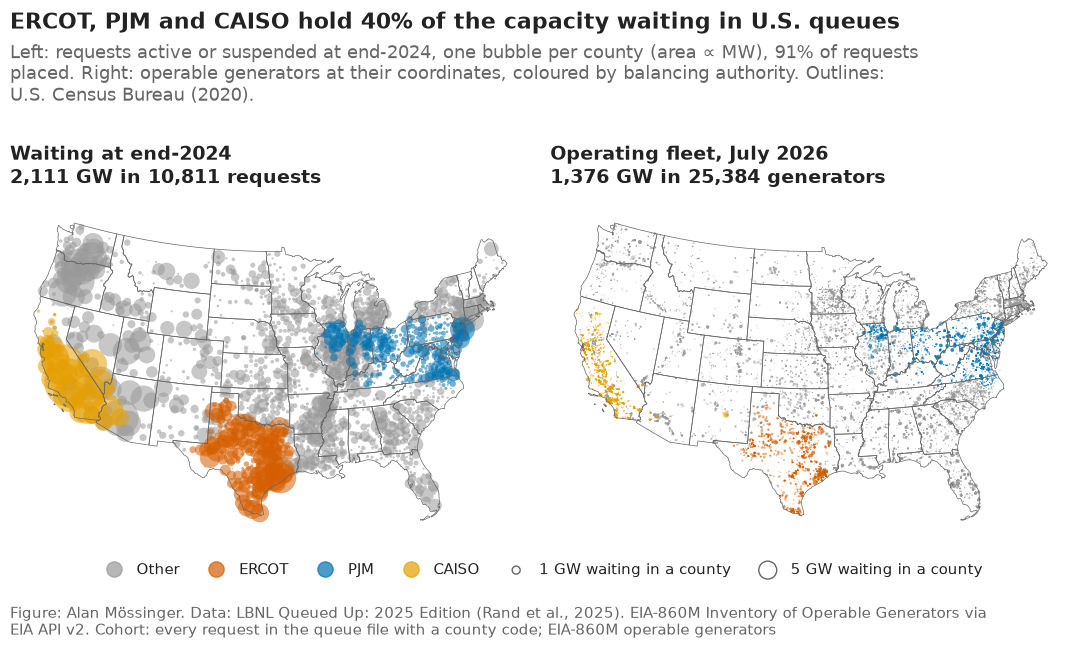

In [31]:
def draw_outline(ax):
    states.boundary.plot(ax=ax, color=MUTED, linewidth=0.5)
    ax.set_axis_off()
    ax.grid(False)


fig, (ax_q, ax_f) = plt.subplots(1, 2, figsize=(11, 6.5))
MW_PER_POINT = 30  # bubble area in points² = MW / 30, so area is proportional to capacity

draw_outline(ax_q)
for region in ["Other"] + TRACK_A:  # grey first so the ISO colours stay on top
    sub = by_county[by_county["region"].isin(TRACK_A) == (region != "Other")]
    sub = sub if region == "Other" else sub[sub["region"] == region]
    ax_q.scatter(sub.geometry.x, sub.geometry.y, s=sub["mw"] / MW_PER_POINT,
                 color=plots.region_color(region), alpha=0.55, linewidths=0, label=region)
ax_q.set_anchor("N")  # maps sit right under their titles; the free band below holds the legend
ax_q.set_title(f"Waiting at end-2024\n{waiting['mw'].sum() / 1e3:,.0f} GW in {len(waiting):,} requests")

draw_outline(ax_f)
for region in ["Other"] + TRACK_A:
    sub = fleet[fleet["region"] == region]
    ax_f.scatter(sub.geometry.x, sub.geometry.y, s=0.6 + sub["nameplate-capacity-mw"] / 120,
                 color=plots.region_color(region), alpha=0.45, linewidths=0, label=region)
ax_f.set_title(f"Operating fleet, July 2026\n{fleet['nameplate-capacity-mw'].sum() / 1e3:,.0f} GW "
               f"in {len(fleet):,} generators")
ax_f.set_anchor("N")

# legend handles with fixed sizes: a region's handle must not inherit the size of its first bubble
handles = [Line2D([], [], marker="o", linestyle="", markersize=11, color=plots.region_color(r), alpha=0.7, label=r)
           for r in ["Other"] + TRACK_A]
handles += [plt.scatter([], [], s=gw * 1e3 / MW_PER_POINT, facecolors="none", edgecolors=MUTED, linewidths=1,
                        label=f"{gw} GW waiting in a county") for gw in (1, 5)]

plots.finish(
    fig,
    f"ERCOT, PJM and CAISO hold {share_track_a:.0%} of the capacity waiting in U.S. queues",
    f"Left: requests active or suspended at end-2024, one bubble per county (area ∝ MW), "
    f"{points['matched'].mean():.0%} of requests placed. Right: operable generators at their coordinates, "
    f"coloured by balancing authority. Outlines: U.S. Census Bureau (2020).",
    cohort="every request in the queue file with a county code; EIA-860M operable generators",
    eia=True)
fig.legend(handles=handles, loc="lower center", bbox_to_anchor=(0.5, 0.085), ncol=6, fontsize=11,
           columnspacing=1.4, handletextpad=0.5)
plots.save_fig(fig, "F9_project_map",
               "Requests waiting in U.S. interconnection queues at end-2024 by county (left) and the "
               "operating fleet from EIA-860M (right), with ERCOT, PJM and CAISO in their fixed colours.",
               "02_eda")
plt.show()

**Reading this.** The left panel is the portfolio manager's territory: 2,111 GW waiting in 10,811 placed requests, and 40% of that capacity in the three ISOs this project can time. Texas alone holds 19% of the waiting capacity (409 GW), California 250 GW; the next largest states are Oregon (127 GW), Arizona (106 GW) and Illinois (92 GW), all in regions where the public file gives no usable event dates, so a book there can be ranked by Track B but not timed. The right panel shows the fleet the queue would join: 1,376 GW in 25,384 generators, dense in the east and along the coasts and thin in the mountain west, where the queue's largest grey bubbles sit. The contrast between the two panels is the point: the queue is where the fleet is not. Two caveats: a bubble is a county total, not a site, and ERCOT is understated because a fifth of its requests carry no county code.

## 4. Share built, by state

A companion map for the portfolio reader: among requests that entered in 2010–2018 and have resolved (operational or withdrawn) by end-2024, the share that reached operation, by state. States with fewer than 30 resolved requests are hatched, because a share on so few requests is noise. This is the same quantity as the region × technology base rates of notebook 03, cut by state instead.

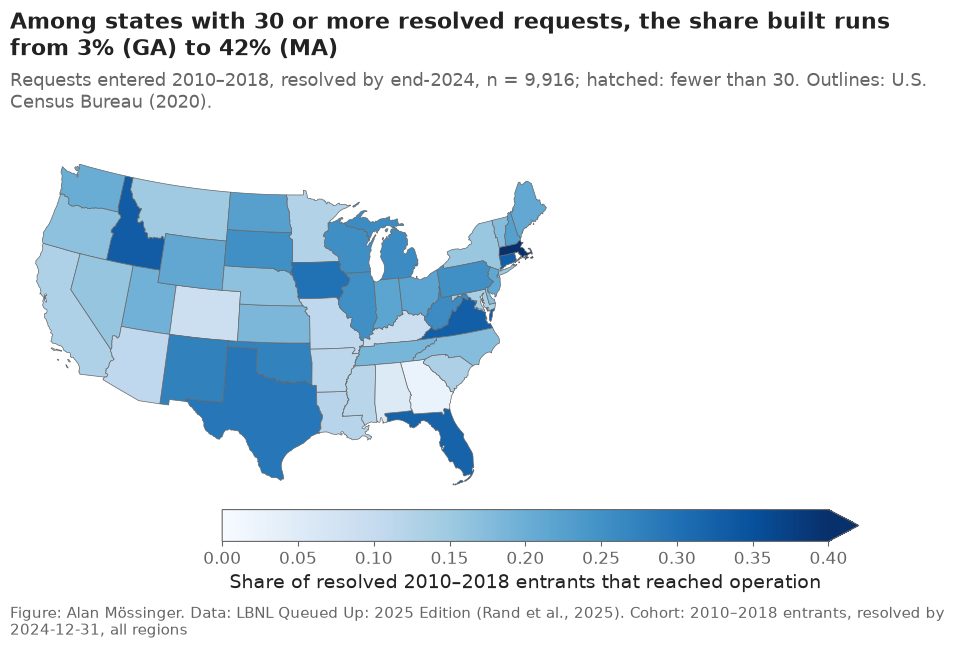

,resolved,operational,share_built,enough
state,,,,
MA,83,35,0.422,True
ID,196,65,0.332,True
CT,61,20,0.328,True
VA,382,125,0.327,True
FL,308,99,0.321,True
IA,110,33,0.300,True
TX,721,209,0.290,True
NM,160,44,0.275,True


In [32]:
resolved = points[points["q_year"].between(2010, 2018) & points["q_status"].isin(["operational", "withdrawn"])]
built = (resolved.groupby("state")
         .agg(resolved=("q_status", "size"), operational=("q_status", lambda s: int((s == "operational").sum())))
         .assign(share_built=lambda d: (d["operational"] / d["resolved"]).round(3)))
built["enough"] = built["resolved"] >= 30
built.to_csv(paths.RESULTS / "map_built_share_by_state.csv")

layer = states.merge(built, left_on="STUSPS", right_index=True, how="left")
fig, ax = plt.subplots(figsize=(11, 6.5))
layer[layer["enough"] == True].plot(column="share_built", cmap="Blues", ax=ax, linewidth=0.5, edgecolor=MUTED,
                                    legend=True, vmin=0, vmax=0.4,
                                    legend_kwds={"label": "Share of resolved 2010–2018 entrants that reached operation",
                                                 "orientation": "horizontal", "shrink": 0.6, "pad": 0.02})
layer[layer["enough"] != True].plot(ax=ax, facecolor="white", edgecolor=MUTED, linewidth=0.5, hatch="///")
ax.set_axis_off(); ax.grid(False)
ax.set_anchor("W")  # map at the left edge, so the title aligns with it and the subtitle has the full width

top = built[built["enough"]].sort_values("share_built", ascending=False)
plots.finish(
    fig,
    f"Among states with 30 or more resolved requests, the share built runs from "
    f"{top['share_built'].iloc[-1]:.0%} ({top.index[-1]}) to {top['share_built'].iloc[0]:.0%} ({top.index[0]})",
    f"Requests entered 2010–2018, resolved by end-2024, n = {int(built['resolved'].sum()):,}; "
    f"hatched: fewer than 30. Outlines: U.S. Census Bureau (2020).",
    cohort="2010–2018 entrants, resolved by 2024-12-31, all regions")
plots.save_fig(fig, "03b_02_built_share_by_state",
               "Share of resolved 2010–2018 entrants that reached operation, by state; states with fewer "
               "than 30 resolved requests hatched.",
               "02_eda", folder="02_eda")
plt.show()
top.head(8)

**Reading this.** Among the states with 30 or more resolved 2010–2018 entrants, the share that reached operation runs from 3% in Georgia and 5% in Alabama to 42% in Massachusetts (on 83 requests), 33% in Idaho and Virginia and 32% in Florida. The three timing ISOs sit apart: Texas 29% of 721, Pennsylvania 25% of 436, Illinois 25% and Ohio 22%, California 13% of 941. This is the state-level version of the region × technology base rates of notebook 03 and it is what the fair baseline of notebook 11 will have to beat; the map also shows why state carries so much of the regional signal in the LightGBM explanation of notebook 09. Colour reads by itself; the hatched states have too few resolved requests for their share to mean anything.

## 5. State archetypes: what kinds of market the queue contains (F25)

A company choosing where to look does not start from 48 states one by one. This section lets the data group them, without being told the outcome, on seven market features that exist in the files: the waiting queue relative to the operating fleet (GW waiting at end-2024 over EIA-860M nameplate), the shares of the waiting MW that are solar, storage (batteries and solar-plus-storage) and gas, the median size of a waiting request, the share of the waiting MW that entered in 2022–2024 (how hot the queue is) and the share of resolved 2010–2018 entrants that reached operation (the history). Features are standardised, reduced with principal components for the picture, and clustered with k-means; k is chosen by silhouette over 3–6 on the 48 states with 30 or more resolved entrants and then the clusters are tested on something they never saw: the share of 2017–2019 entrants that were operating by the end of 2024. An archetype that does not separate that outcome is a description; one that does is a screen.

In [33]:
import numpy as np
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

from src import drivers

q = queue[queue["state"].notna()].copy()
q["tech"] = q["type_clean"].map(plots.tech_group)
wait = q[q["q_status"].isin(["active", "suspended"])]
fleet_mw = eia[eia["status"] == "OP"].groupby("stateid")["nameplate-capacity-mw"].sum()
feat = pd.DataFrame({
    "queue_over_fleet": wait.groupby("state")["mw"].sum() / fleet_mw.reindex(wait.groupby("state")["mw"].sum().index),
    "solar_share": wait[wait["tech"] == "Solar"].groupby("state")["mw"].sum() / wait.groupby("state")["mw"].sum(),
    "storage_share": wait[wait["tech"].isin(["Battery", "Solar+Battery"])].groupby("state")["mw"].sum() / wait.groupby("state")["mw"].sum(),
    "gas_share": wait[wait["tech"] == "Gas"].groupby("state")["mw"].sum() / wait.groupby("state")["mw"].sum(),
    "median_mw_waiting": wait.groupby("state")["mw"].median(),
    "recent_entry_share": wait[wait["q_year"] >= 2022].groupby("state")["mw"].sum() / wait.groupby("state")["mw"].sum(),
    "share_built_2010_2018": built["share_built"],
}).fillna(0.0)
feat = feat.loc[built.index[built["enough"]]].replace([np.inf, -np.inf], np.nan).dropna()
later = q[q["q_year"].between(2017, 2019)]
outcome = later.groupby("state").agg(n_2017_2019=("q_status", "size"), operating=("q_status", lambda s: int((s == "operational").sum())))
Z = StandardScaler().fit_transform(feat)
sil = {k: silhouette_score(Z, KMeans(n_clusters=k, n_init=20, random_state=3).fit_predict(Z)) for k in range(3, 7)}
K_BEST = max(sil, key=sil.get)
km = KMeans(n_clusters=K_BEST, n_init=20, random_state=3).fit(Z)
pca = PCA(n_components=2, random_state=3).fit(Z)
coords = pca.transform(Z)
arch = feat.assign(archetype=km.labels_, pc1=coords[:, 0], pc2=coords[:, 1]).join(outcome)
profile = arch.groupby("archetype").agg(states=("pc1", "size"), **{c: (c, "median") for c in feat.columns},
                                        n_2017_2019=("n_2017_2019", "sum"), operating=("operating", "sum"))
profile["completion_2017_2019"] = profile["operating"] / profile["n_2017_2019"]
profile["low"], profile["high"] = drivers.wilson(profile["operating"], profile["n_2017_2019"])
profile = profile.sort_values("completion_2017_2019", ascending=False)
NAMES = {}
for a, r in profile.iterrows():
    hot = "hot" if r["recent_entry_share"] >= profile["recent_entry_share"].median() else "settled"
    mix = "storage-heavy" if r["storage_share"] >= 0.35 else ("solar-heavy" if r["solar_share"] >= 0.45 else ("gas-leaning" if r["gas_share"] >= 0.15 else "mixed"))
    load = "crowded" if r["queue_over_fleet"] >= profile["queue_over_fleet"].median() else "light"
    NAMES[a] = f"{load} queue, {mix}, {hot}"
profile["name"] = pd.Series(NAMES)
arch["name"] = arch["archetype"].map(NAMES)
arch["state_list"] = ""
arch.round(4).to_csv(paths.RESULTS / "state_archetypes.csv")
profile.assign(state_list=arch.groupby("archetype")["name"].apply(lambda s: ", ".join(sorted(s.index)))).round(3).to_csv(paths.RESULTS / "archetype_profiles.csv")
sep = profile["completion_2017_2019"].max() - profile["completion_2017_2019"].min()
print(f"{len(feat)} states; silhouette by k: { {k: round(v, 3) for k, v in sil.items()} } → k = {K_BEST}; explained variance of two components {pca.explained_variance_ratio_.sum():.0%}")
print(f"2017–2019 completion by end-2024 runs from {profile['completion_2017_2019'].min():.1%} to {profile['completion_2017_2019'].max():.1%} across archetypes (spread {sep:.1%})")
for a, r in profile.iterrows():
    print(f"  A{a + 1} {r['name']}: {', '.join(sorted(arch.index[arch['archetype'] == a]))}")
profile[["name", "states"] + list(feat.columns) + ["n_2017_2019", "completion_2017_2019", "low", "high"]].round(3)

47 states; silhouette by k: {3: 0.202, 4: 0.203, 5: 0.202, 6: 0.203} → k = 4; explained variance of two components 52%
2017–2019 completion by end-2024 runs from 5.5% to 19.7% across archetypes (spread 14.2%)
  A1 light queue, mixed, settled: DE, FL, MD, MT, OH, PA, VA, WV
  A4 crowded queue, storage-heavy, hot: CT, IA, ID, IL, IN, MA, ME, MI, ND, NH, NJ, NM, NY, OK, SD, TX, VT, WA, WI, WY
  A3 crowded queue, storage-heavy, settled: AZ, CA, NV, OR, UT
  A2 light queue, gas-leaning, hot: AL, AR, CO, GA, KS, KY, LA, MN, MO, MS, NC, NE, SC, TN


,name,states,queue_over_fleet,solar_share,storage_share,gas_share,median_mw_waiting,recent_entry_share,share_built_2010_2018,n_2017_2019,completion_2017_2019,low,high
archetype,,,,,,,,,,,,,
0,"light queue, mixed, settled",8,0.794,0.379,0.300,0.034,55.250,0.305,0.236,1358,0.197,0.177,0.219
3,"crowded queue, storage-heavy, hot",20,1.430,0.234,0.378,0.026,150.000,0.678,0.252,2565,0.115,0.103,0.128
2,"crowded queue, storage-heavy, settled",5,3.500,0.047,0.795,0.030,254.855,0.542,0.159,895,0.070,0.055,0.089
1,"light queue, gas-leaning, hot",14,1.212,0.423,0.262,0.160,151.750,0.674,0.119,1287,0.055,0.044,0.069


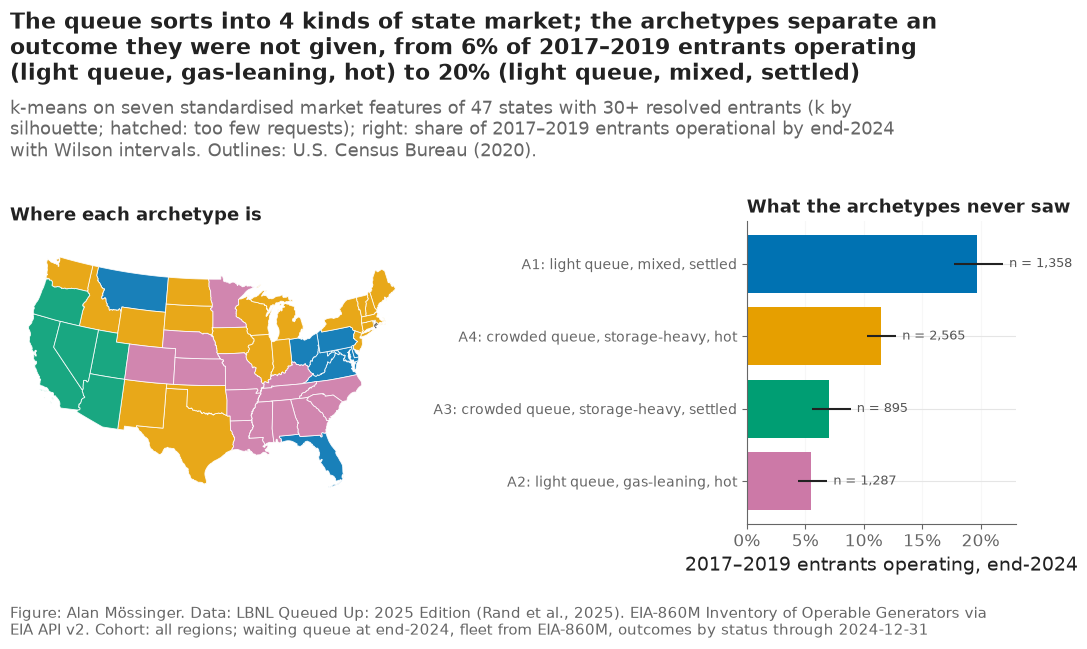

In [34]:
ARCH_COLORS = ["#0072B2", "#E69F00", "#009E73", "#CC79A7", "#56B4E9", "#D55E00"]
colour_of = {a: ARCH_COLORS[i] for i, a in enumerate(profile.index)}
fig, axes = plt.subplots(1, 2, figsize=(11, 6.5), gridspec_kw={"width_ratios": [1.5, 1]})
ax = axes[0]
layer = states.merge(arch[["archetype"]], left_on="STUSPS", right_index=True, how="left")
layer[layer["archetype"].isna()].plot(ax=ax, facecolor="white", edgecolor=MUTED, linewidth=0.5, hatch="///")
for a in profile.index:
    part = layer[layer["archetype"] == a]
    if len(part):
        part.plot(ax=ax, facecolor=colour_of[a], edgecolor="white", linewidth=0.6, alpha=0.9)
ax.set_axis_off(); ax.grid(False)
ax.set_title("Where each archetype is", fontsize=13, loc="left")
ax = axes[1]
y = np.arange(len(profile))
ax.barh(y, profile["completion_2017_2019"], color=[colour_of[a] for a in profile.index])
ax.hlines(y, profile["low"], profile["high"], color=plots.INK, lw=1.5)
for yy, (a, r) in zip(y, profile.iterrows()):
    ax.text(r["high"] + 0.005, yy, f"n = {int(r['n_2017_2019']):,}", va="center", fontsize=9.5, color="#555555")
ax.set_yticks(y)
ax.set_yticklabels([f"A{a + 1}: {r['name']}" for a, r in profile.iterrows()], fontsize=10)
ax.invert_yaxis()
ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
ax.set_xlabel("2017–2019 entrants operating, end-2024")
ax.set_title("What the archetypes never saw", fontsize=13, loc="left")
ax.grid(axis="x", alpha=0.3)
best, worst = profile.iloc[0], profile.iloc[-1]
plots.finish(fig,
             f"The queue sorts into {K_BEST} kinds of state market; the archetypes separate an outcome they were not given, "
             f"from {worst['completion_2017_2019']:.0%} of 2017–2019 entrants operating ({worst['name']}) to {best['completion_2017_2019']:.0%} ({best['name']})",
             f"k-means on seven standardised market features of {len(feat)} states with 30+ resolved entrants (k by silhouette; hatched: too few requests); "
             f"right: share of 2017–2019 entrants operational by end-2024 with Wilson intervals. Outlines: U.S. Census Bureau (2020).",
             cohort="all regions; waiting queue at end-2024, fleet from EIA-860M, outcomes by status through 2024-12-31", eia=True)
plots.save_fig(fig, "F25_state_archetypes", "State archetypes from k-means on seven market features (queue relative to the fleet, technology mix of the waiting MW, median request size, recent-entry share, historical share built), mapped, and the share of 2017–2019 entrants operating by end-2024 in each archetype with Wilson intervals.", "02_eda")
plt.show()

**Reading this.** Four kinds of state market come out of seven features, and the structure is soft (silhouette about 0.20 for every k from 3 to 6, so k is a choice more than a discovery), but the archetypes separate an outcome they were never given: the share of 2017–2019 entrants operating by the end of 2024 runs from 5.5% to 19.7% across them.

- **A1, a light, settled queue with a mixed technology list** (DE, FL, MD, MT, OH, PA, VA, WV: the PJM core and Florida): queue below the fleet (0.8×), 31% of the waiting MW entered since 2022, a history of 24% built, and 19.7% of 2017–2019 entrants operating. This is where entry odds are best.
- **A4, a crowded, hot, storage-heavy queue** (20 states from New England and the upper Midwest to Texas and the mountain west): queue 1.4× the fleet, two thirds of it entered since 2022, 11.5% of 2017–2019 entrants operating. Texas sits here: its base rate is high but its queue has doubled.
- **A3, the crowded, settled, storage-dominated Southwest** (AZ, CA, NV, OR, UT): queue 3.5× the fleet, 80% of the waiting MW is storage or hybrids, 7.0% operating. Entry odds are a third of A1's, and the plants waiting are the ones with negative merchant NPV in notebook 15.
- **A2, a light, hot, gas-leaning queue** (AL, AR, CO, GA, KS, KY, LA, MN, MO, MS, NC, NE, SC, TN: the Southeast and plains): 16% gas in the waiting MW, a history of 12% built and 5.5% operating. Most of these states are outside the three timing ISOs, so the public file dates few of their outcomes.

For a company the map is a first screen, not a ranking of states: look in A1 for entry, in A4 only where the agreement can be dated (Texas), treat A3 as a market that needs a contract, and A2 as one the public data cannot yet time.

## 6. Checks

In [35]:
checks = pd.DataFrame([
    {"check": "state totals on the map equal the clean file",
     "value": int(by_state.filter(like="n_").sum().sum()), "expected": int(points["state"].notna().sum()),
     "pass": int(by_state.filter(like="n_").sum().sum()) == int(points["state"].notna().sum())},
    {"check": "requests without a county position ≤ 10%",
     "value": round(float((~points["matched"]).mean()), 3), "expected": "≤ 0.10",
     "pass": bool((~points["matched"]).mean() <= 0.10)},
    {"check": "archetypes separate the 2017–2019 outcome (spread ≥ 5 points) and F25 saved",
     "value": round(float(sep), 3), "expected": "≥ 0.05",
     "pass": bool(sep >= 0.05) and (paths.FIGURES / "F25_state_archetypes.png").exists()},
    {"check": "F9 saved as PNG and SVG",
     "value": int((paths.FIGURES / "F9_project_map.png").exists()) + int((paths.FIGURES / "F9_project_map.svg").exists()),
     "expected": 2,
     "pass": (paths.FIGURES / "F9_project_map.png").exists() and (paths.FIGURES / "F9_project_map.svg").exists()},
])
checks.to_csv(paths.RESULTS / "map_checks.csv", index=False)
assert checks["pass"].all(), checks
checks

,check,value,expected,pass
0,state totals on the map equal the clean file,36155.000,36155,True
1,requests without a county position ≤ 10%,0.086,≤ 0.10,True
2,archetypes separate the 2017–2019 outcome (spr...,0.142,≥ 0.05,True
3,F9 saved as PNG and SVG,2.000,2,True


## Takeaways — Part B

- 91.4% of the 36,216 requests in the clean file can be placed by county; the gap is in MISO (35% without a code) and ERCOT (21%).
- At end-2024, 2,111 GW were waiting in 10,811 placed requests; ERCOT, PJM and CAISO hold 40% of that capacity, Texas alone 19%.
- The waiting queue is densest where the operating fleet (1,376 GW, 25,384 generators) is thinnest: the mountain west and the southern plains.
- The share of resolved 2010–2018 entrants that reached operation runs from 3% (Georgia) to 42% (Massachusetts) across states with 30 or more; Texas 29%, Pennsylvania 25%, California 13%.
- **State archetypes (section 5, F25):** k-means on seven market features sorts 47 states into four kinds of market; the archetypes separate the share of 2017–2019 entrants operating by end-2024 (5.5% in the hot gas-leaning Southeast and plains, 7.0% in the storage-dominated Southwest, 11.5% in the crowded hot queues that include Texas, 19.7% in the light settled queues of the PJM core and Florida).
- **What goes to the report:** F25 as the opening of the "where is the opportunity" section; F9 in the data section as the geography of the decision; the state map as a companion to the base rates; `results/map_unmatched.csv` for the limitations.

## Takeaways

- **Part A** — Explore survival curves: its *Takeaways — Part A* cell above says what it found and what goes to the report.
- **Part B** — Where the queue and the built fleet are (figure F9): its *Takeaways — Part B* cell above says what it found and what goes to the report.

**What goes to the report.** Report figures drawn here: F1_cif_by_region, F2_operation_by_technology, F3_five_year_by_size, F8_congestion_vs_completion, F19_drivers, F20_when_requests_die, F9_project_map, F25_state_archetypes. Every number the report cites from this notebook is read from `results/` by `src/report_numbers.py`.